# Part B: Energy Consumption Forecasting (Time Series)

## Project Overview

The aim of this project is to forecast a building's monthly **gas, electricity and water consumption** for the next **60 months**, so that utility budgets and capacity can be planned ahead. Because each value depends on the values before it, this is a **time series forecasting** problem.

**Dataset:** `CA2-Energy-Consumption-Data.csv`: **397 monthly records (January 1990 – January 2023)**

| Column | Unit |
|---|---|
| `DATE` | Month of the reading (stored as day/month/year) |
| `Gas Consumption (tons)` | tons |
| `Electricity Consumption (MWh)` | MWh |
| `Water Consumption (tons)` | tons |

**Workflow**

1. **Setup & Data Loading:** parsing dates correctly and checking the monthly frequency.
2. **Exploratory Data Analysis (EDA):** outliers, seasonal decomposition and correlation between utilities.
3. **Train / Validation / Test Split:** chronological 80 / 10 / 10 split.
4. **Stationarity Check:** ADF test, rolling statistics and visual inspection, used together to decide whether each series needs differencing.
5. **Baseline Models:** several candidate models for each utility, compared against simple benchmarks.
6. **Hyperparameter Tuning:** grid search scored on **four validation windows** (rolling-origin validation), including how much differencing to use.
7. **Test Set Evaluation & Residual Analysis:** final models retrained on train + validation, scored once on the test set, and their residuals checked for leftover patterns.
8. **60-Month Forecast** with 95% confidence intervals.
9. **Model Improvement Analysis:** the effect of seasonality, of tuning, and of keeping the February 2014 outlier.

## Step 1: Setup & Load Data
### 1.1 Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
# The grid searches fit hundreds of models and statsmodels prints optimiser messages for many of them.
# They are hidden to keep the output readable; convergence of every FINAL model is checked explicitly in Step 7.
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

GAS, ELEC, WATER = "Gas Consumption (tons)", "Electricity Consumption (MWh)", "Water Consumption (tons)"
UTILITIES = [GAS, ELEC, WATER]
COLORS = {GAS: "#E4572E", ELEC: "#17A398", WATER: "#3D7DCA"}

### 1.2 Loading the Dataset & Parsing Dates

The `DATE` column is written **day-first** (e.g. `1/2/1990` means **1 February 1990**). Without `dayfirst=True`, pandas reads it month-first, and every month turns into a *day in January* (February 1990 becomes 2 January 1990). That would make every time-based plot and date label wrong. The frequency check below confirms the parsed dates are one row per month, with no gaps.

In [2]:
# Relative path: keep the CSV in the same folder as this notebook
df = pd.read_csv("CA2-Energy-Consumption-Data.csv")
df["DATE"] = pd.to_datetime(df["DATE"], dayfirst=True)
df = df.set_index("DATE").sort_index()
df.index.freq = pd.infer_freq(df.index)     # set monthly frequency for statsmodels

print("Date range:", df.index.min().strftime("%b %Y"), "to", df.index.max().strftime("%b %Y"))
print("Detected frequency:", df.index.freq, "(MS = month start)")
print("Rows:", len(df), "| Missing values:", int(df.isnull().sum().sum()))
df.head()

Date range: Jan 1990 to Jan 2023
Detected frequency: <MonthBegin> (MS = month start)
Rows: 397 | Missing values: 0


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
DATE,,,
1990-01-01,18.0,725.1,548.8
1990-02-01,15.8,706.7,640.7
1990-03-01,17.3,624.5,511.1
1990-04-01,18.9,574.7,515.3
1990-05-01,22.0,553.2,488.4


In [3]:
df.describe().round(2)

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
count,397.00,397.00,397.00
mean,23.79,888.47,484.95
std,4.90,153.88,133.91
min,11.60,553.20,44.40
25%,20.20,771.10,384.40
50%,23.50,897.80,487.40
75%,27.90,1005.20,580.20
max,46.00,1294.00,811.00


**Observations**

- **397 consecutive monthly readings** with **no missing values**.
- **Gas** is the most stable: a mean of 23.8 tons, with half of all months between 20.2 and 27.9 tons. The maximum (**46 tons**) is about **2× the normal level**, which needs checking.
- **Electricity** ranges from **553 to 1,294 MWh**. Its standard deviation (154 MWh) is high mainly because of a **long-term upward trend** (shown in Step 2), not just month-to-month noise.
- **Water** varies the most relative to its size. Its middle 50% spans **384–580 tons**, and its minimum (**44 tons**) is about **10× below** the typical level, which also needs checking.

## Step 2: Exploratory Data Analysis (EDA)
### 2.1 Outlier Detection (Z-score > 3)

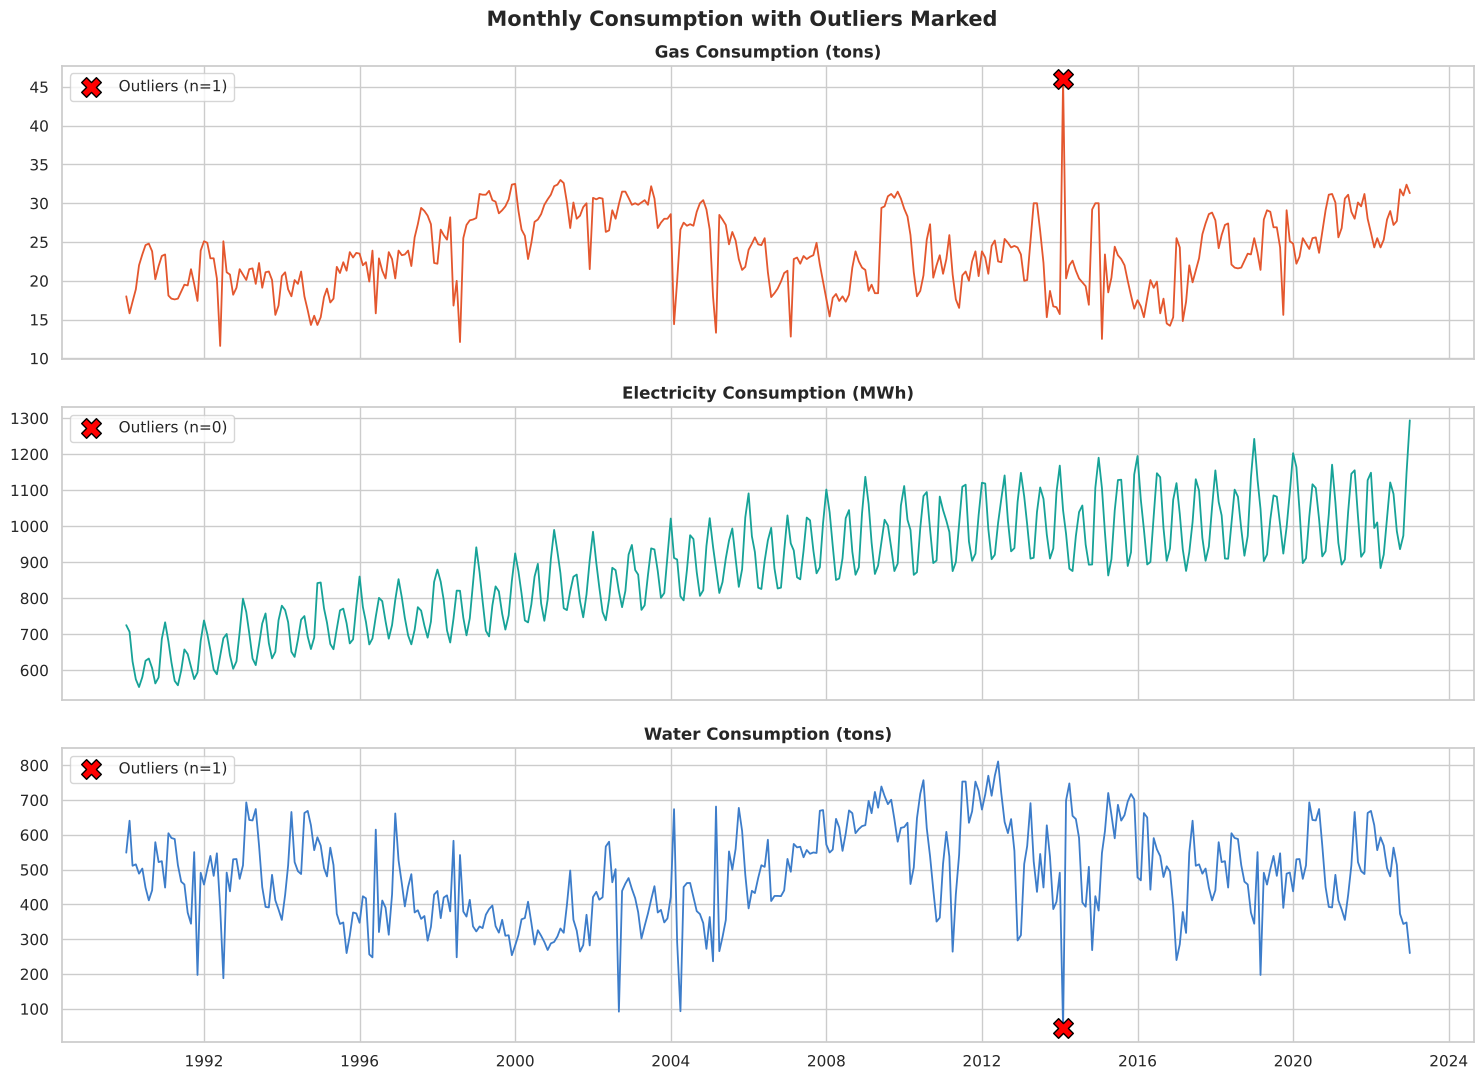

,Utility,Month,Value,Z-score
0,Gas Consumption (tons),Feb 2014,46.0,4.54
1,Water Consumption (tons),Feb 2014,44.4,3.29


In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
outlier_rows = []
for ax, u in zip(axes, UTILITIES):
    z = np.abs(stats.zscore(df[u]))
    out = df[z > 3]
    ax.plot(df.index, df[u], color=COLORS[u], linewidth=1.3)
    ax.scatter(out.index, out[u], color="red", s=200, marker="X", edgecolors="black", zorder=5,
               label=f"Outliers (n={len(out)})")
    ax.set_title(u, fontsize=12, fontweight="bold"); ax.legend(loc="upper left")
    for d, v, zz in zip(out.index, out[u], z[z > 3]):
        outlier_rows.append({"Utility": u, "Month": d.strftime("%b %Y"), "Value": v, "Z-score": round(zz, 2)})
plt.suptitle("Monthly Consumption with Outliers Marked", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()
pd.DataFrame(outlier_rows)

- **Gas: 1 outlier.** **46 tons in February 2014** (Z = 4.54), about 2× the usual level.
- **Electricity: no outliers.** Its high values are part of the steady upward trend, not isolated spikes.
- **Water: 1 outlier.** **44 tons**, also in **February 2014** (Z = 3.29).

Both anomalies happen in the **same month**: gas use doubled while water use almost stopped. A single event, such as a plant shutdown, a maintenance period or a metering problem, is more likely than two independent coincidences.

These points are **kept**. They fall in the training period, so keeping them lets us check that the models are not thrown off by one unusual month.

### 2.2 Seasonal Decomposition

Each series is split into **trend**, **seasonal (12-month)** and **residual** parts using additive decomposition.

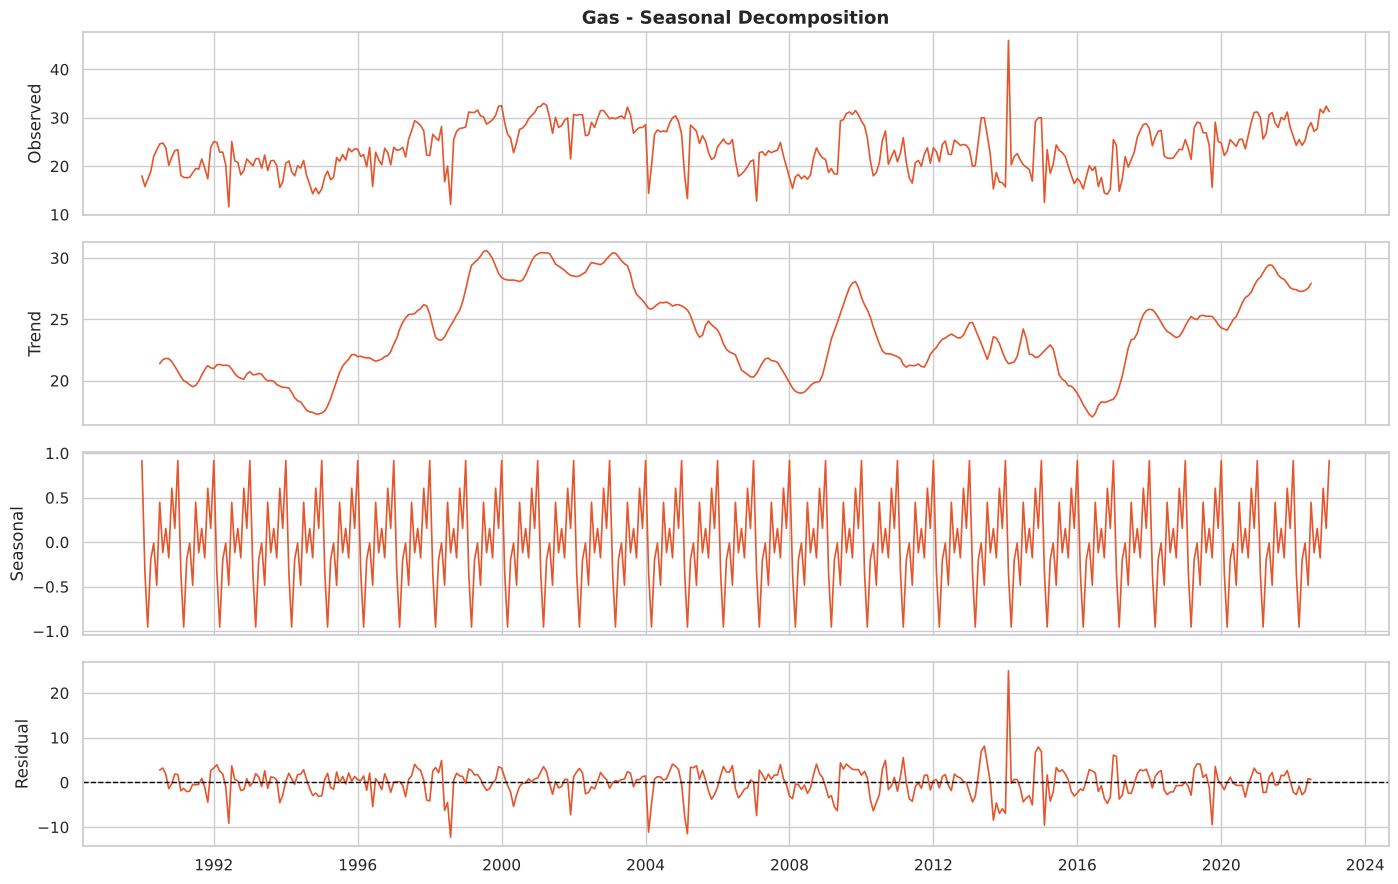

In [5]:
def plot_decomposition(series, title, color):
    dec = seasonal_decompose(series, model="additive", period=12)
    fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
    for ax, part, name in zip(axes, [dec.observed, dec.trend, dec.seasonal, dec.resid],
                              ["Observed", "Trend", "Seasonal", "Residual"]):
        ax.plot(part, color=color, linewidth=1.2); ax.set_ylabel(name)
    axes[3].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[0].set_title(f"{title} - Seasonal Decomposition", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()
    return dec

gas_dec = plot_decomposition(df[GAS], "Gas", COLORS[GAS])

**Gas**
- **Trend:** no long-term growth, but the level **drifts in long waves** rather than staying flat. It is low in the mid-1990s and around 2016 (about 17 tons), high in 2000–2003 (about 30 tons), and has been **rising again since 2017** to about 28–29 tons by 2021.
- **Seasonal:** a very small repeating pattern of about ±1 ton, so seasonality is **weak**.
- **Residual:** mostly within ±5 tons, apart from one large spike at the **February 2014** outlier.

Gas has no seasonality to model, but its slowly drifting level means a model that assumes a constant average may fall behind when the level shifts.

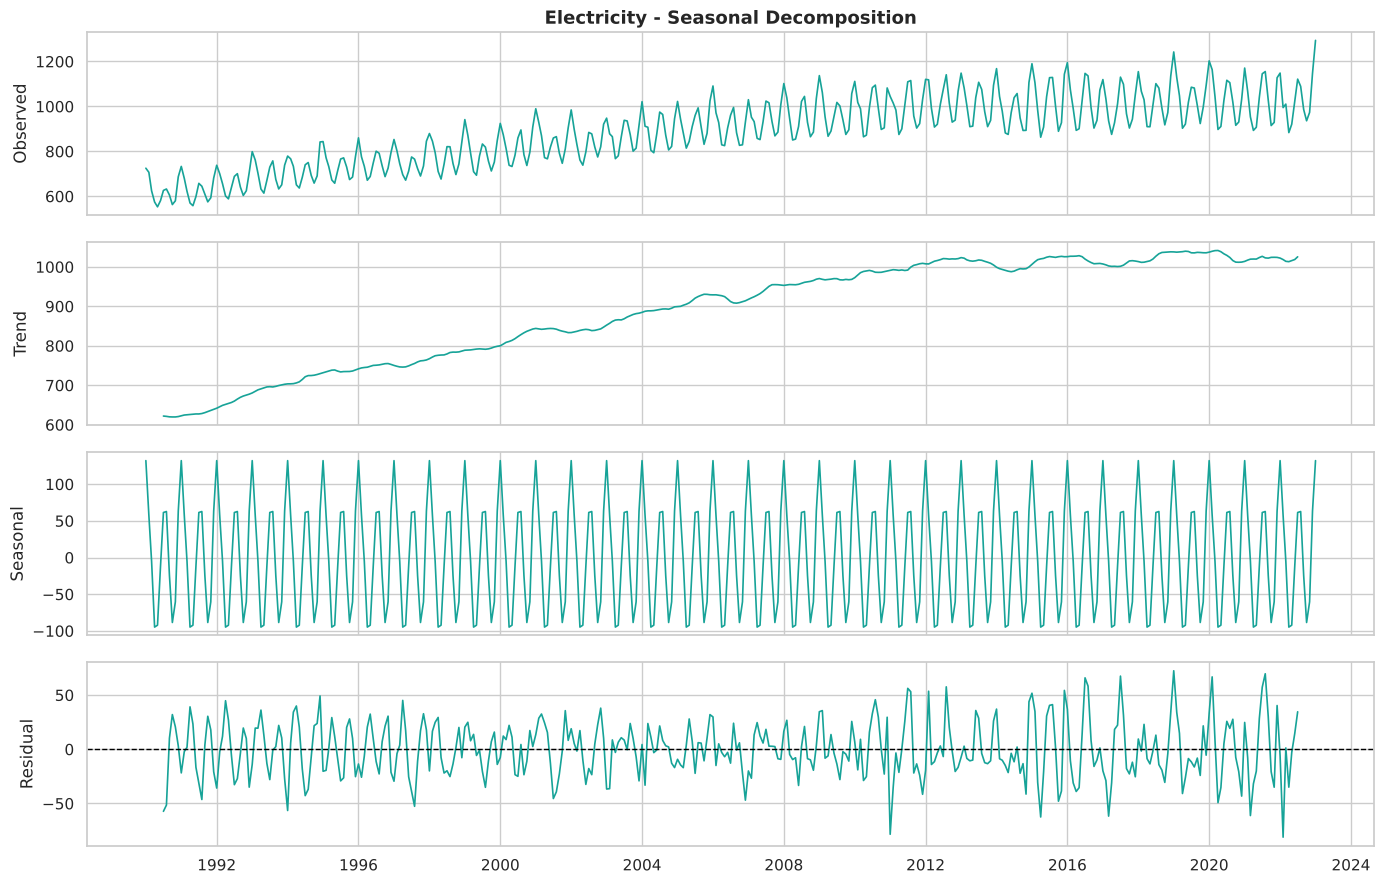

In [6]:
elec_dec = plot_decomposition(df[ELEC], "Electricity", COLORS[ELEC])

**Electricity**
- **Trend:** a steady rise from about **620 MWh (1990) to about 1,030 MWh (around 2013)**. After that it **levels off** at around 1,000–1,040 MWh.
- **Seasonal:** a **strong, regular 12-month cycle** of about −95 to +135 MWh, repeated every year.
- **Residual:** mostly within ±50 MWh, slightly wider after 2010, so trend and seasonality explain most of the variation.

Electricity has both a **trend** and **strong seasonality**, so a seasonal model (SARIMA or Holt-Winters) is needed.

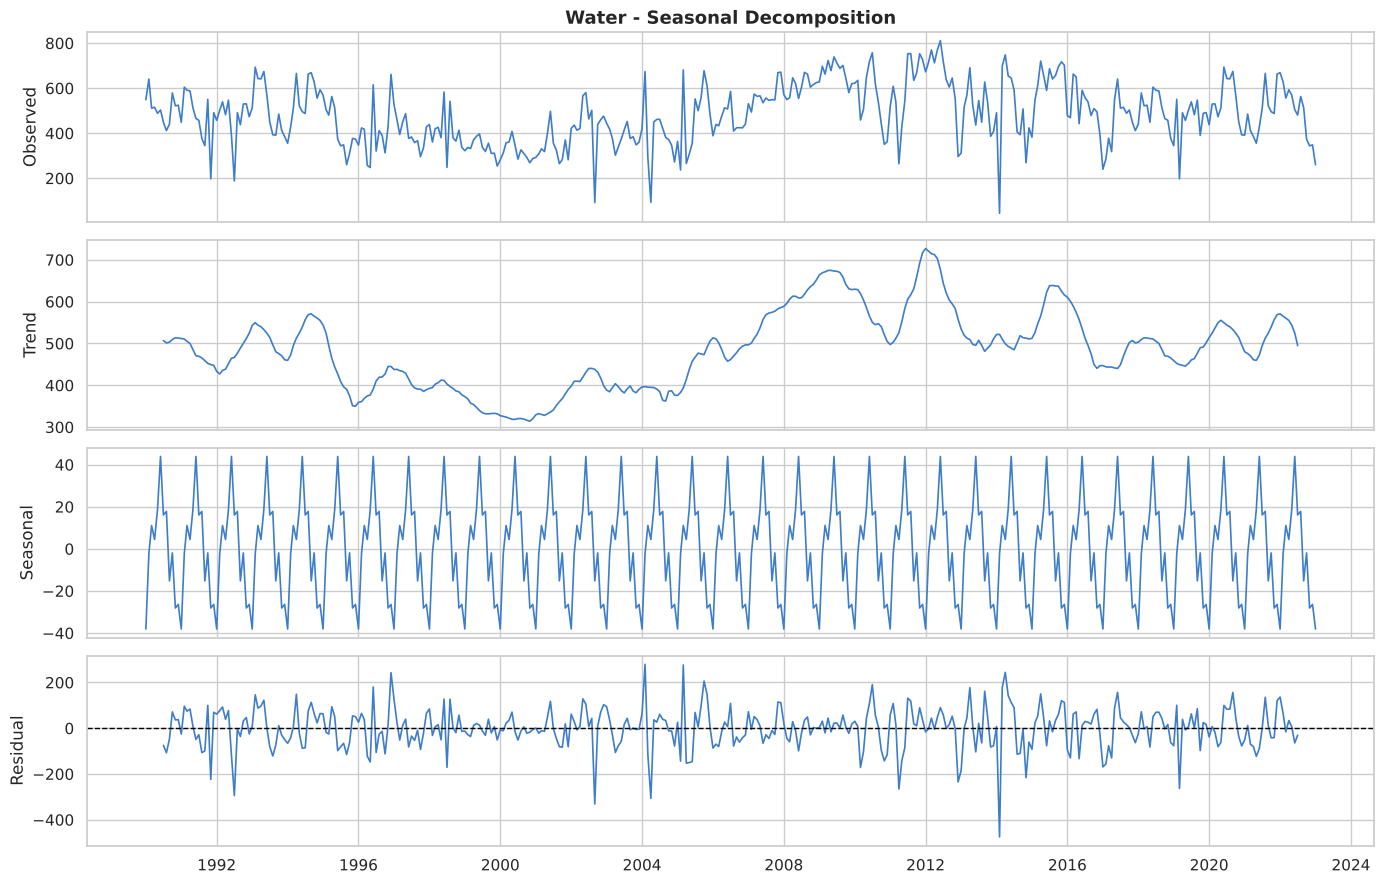

In [7]:
water_dec = plot_decomposition(df[WATER], "Water", COLORS[WATER])

**Water**
- **Trend:** wanders between about **320 and 730 tons** with no consistent direction. It falls to about 320 around 2000, rises to a peak of about 725 in early 2012, then settles near 500.
- **Seasonal:** a small pattern of about −38 to +45 tons, which is **weak** compared with the overall level.
- **Residual:** **very large** (up to about ±470 tons). Most of water's month-to-month variation is **not explained** by trend or season.

Water is mostly irregular, so it will be the **hardest to forecast**.

### Decomposition Summary

| Utility | Trend | Seasonality | Residual noise | Expected forecastability |
|---|---|---|---|---|
| **Gas** | No growth, slowly drifting level | Weak | Low (one spike) | Moderate |
| **Electricity** | Rising, then levelling | **Strong** | Low | **Very good** |
| **Water** | Wandering | Weak | **High** | Poor |

### 2.3 Correlation Between Utilities

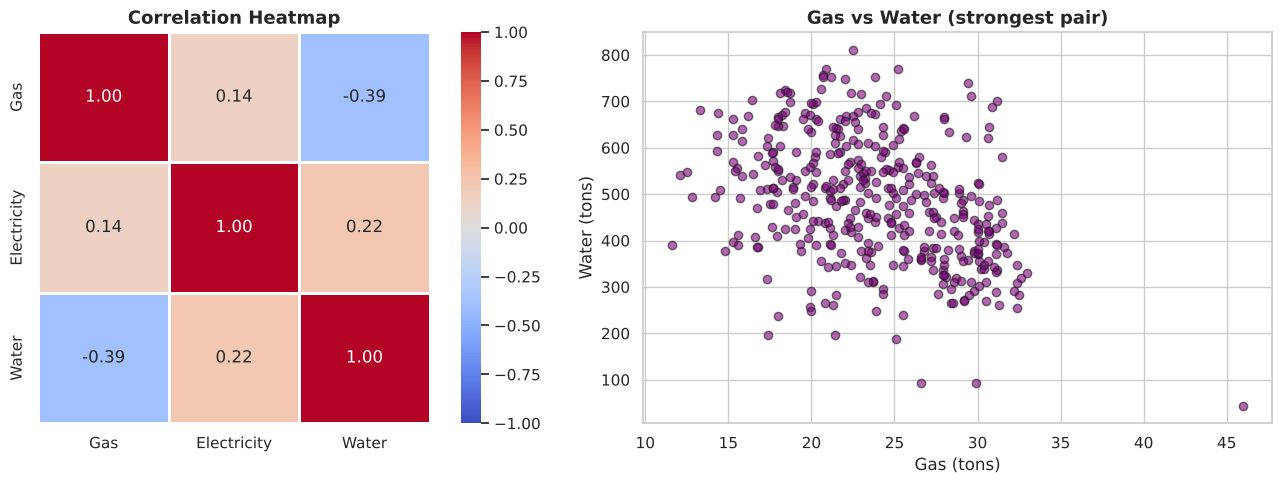

In [8]:
corr = df[UTILITIES].corr()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=1, ax=axes[0], xticklabels=["Gas", "Electricity", "Water"], yticklabels=["Gas", "Electricity", "Water"])
axes[0].set_title("Correlation Heatmap", fontsize=13, fontweight="bold")
axes[1].scatter(df[GAS], df[WATER], alpha=0.6, color="purple", edgecolors="k")
axes[1].set_xlabel("Gas (tons)"); axes[1].set_ylabel("Water (tons)")
axes[1].set_title("Gas vs Water (strongest pair)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

| Pair | Correlation | Strength |
|---|---|---|
| Gas ↔ Electricity | +0.14 | Very weak |
| Electricity ↔ Water | +0.22 | Weak |
| Gas ↔ Water | −0.39 | Moderate, negative |

All correlations are **below 0.4 in absolute value**, so the utilities behave largely **independently**. Using one utility to predict another would add little, so each utility gets its **own model**. The moderate negative gas–water link means months with more gas use tend to have slightly less water use. The February 2014 event is an extreme example of this.

## Step 3: Train / Validation / Test Split

Time series data is **not shuffled**. Shuffling would let the model learn from future months to predict past ones (**data leakage**), and a real forecast only ever has the past to work from. The data is split **chronologically**:

- **Train (80%):** fit the candidate models.
- **Validation (10%):** compare models and tune hyperparameters.
- **Test (10%):** used **once**, at the end, to measure performance on unseen data.

In [9]:
train_size = int(len(df) * 0.80)
val_size = int(len(df) * 0.10)
train = df.iloc[:train_size]
val = df.iloc[train_size:train_size + val_size]
test = df.iloc[train_size + val_size:]

split_df = pd.DataFrame({
    "Rows": [len(train), len(val), len(test)],
    "From": [s.index.min().strftime("%b %Y") for s in (train, val, test)],
    "To":   [s.index.max().strftime("%b %Y") for s in (train, val, test)],
}, index=["Train", "Validation", "Test"])
split_df

,Rows,From,To
Train,317,Jan 1990,May 2016
Validation,39,Jun 2016,Aug 2019
Test,41,Sep 2019,Jan 2023


| Set | Rows | Period |
|---|---|---|
| **Train** | 317 | Jan 1990 – May 2016 |
| **Validation** | 39 | Jun 2016 – Aug 2019 |
| **Test** | 41 | Sep 2019 – Jan 2023 |

The training set covers **more than 26 full yearly cycles**, which is plenty for estimating seasonality. It also includes the February 2014 outlier. The validation and test periods are clean, recent data.

**Why 80 / 10 / 10?** A larger training share gives the models more yearly cycles to learn from. The cost is that a single 39-month validation window is a **small sample**: a model can win just because it happens to suit those three years. Step 6 deals with this by scoring each model on **four** validation windows, all before the test period, instead of one.

**Limitation:** the test set covers 41 months, which is shorter than the 60-month forecast. The test score therefore describes accuracy about 3.5 years ahead. The last 1.5 years of the forecast are less certain than the test score suggests, which is why the confidence intervals in Step 8 keep widening.

## Step 4: Stationarity Check

ARIMA-type models need a **stationary** series, i.e. one whose mean and variance don't change over time. Differencing is a fix for non-stationarity, **not a default preprocessing step**: differencing a series that is already stationary (**over-differencing**) throws away information and adds noise. So each utility is checked separately, using three kinds of evidence:

1. **Augmented Dickey-Fuller (ADF) test:** p < 0.05 means stationary; p ≥ 0.05 means non-stationary.
2. **Rolling statistics:** whether the 12-month rolling mean and standard deviation stay roughly constant.
3. **Visual inspection:** the decomposition plots in Step 2 and the rolling plots below.

All checks use the **training set only**, so the decision doesn't use future data.

In [10]:
rows = []
for u in UTILITIES:
    p_orig = adfuller(train[u])[1]
    p_diff = adfuller(train[u].diff().dropna())[1]
    rows.append({"Utility": u, "ADF p-value (original)": round(p_orig, 4),
                 "Stationary?": "Yes" if p_orig < 0.05 else "No",
                 "ADF p-value (1st difference)": round(p_diff, 4)})
adf_df = pd.DataFrame(rows).set_index("Utility")
adf_df

,ADF p-value (original),Stationary?,ADF p-value (1st difference)
Utility,,,
Gas Consumption (tons),0.3158,No,0.0
Electricity Consumption (MWh),0.4113,No,0.0
Water Consumption (tons),0.0095,Yes,0.0


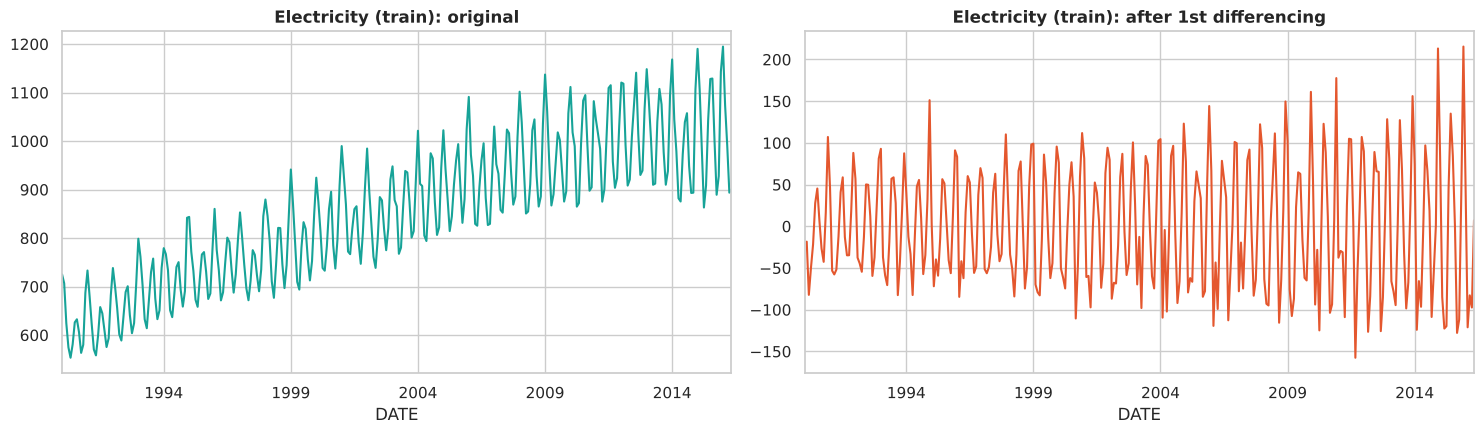

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
train[ELEC].plot(ax=ax[0], color=COLORS[ELEC]); ax[0].set_title("Electricity (train): original", fontweight="bold")
train[ELEC].diff().plot(ax=ax[1], color="#E4572E"); ax[1].set_title("Electricity (train): after 1st differencing", fontweight="bold")
plt.tight_layout()
plt.show()

### 4.1 Rolling Statistics (Training Set)

The ADF test gives a single yes/no answer. Rolling statistics show *how* the mean and spread move over time. A stationary series has a 12-month rolling mean that moves around a fixed level and a rolling standard deviation that stays roughly constant.

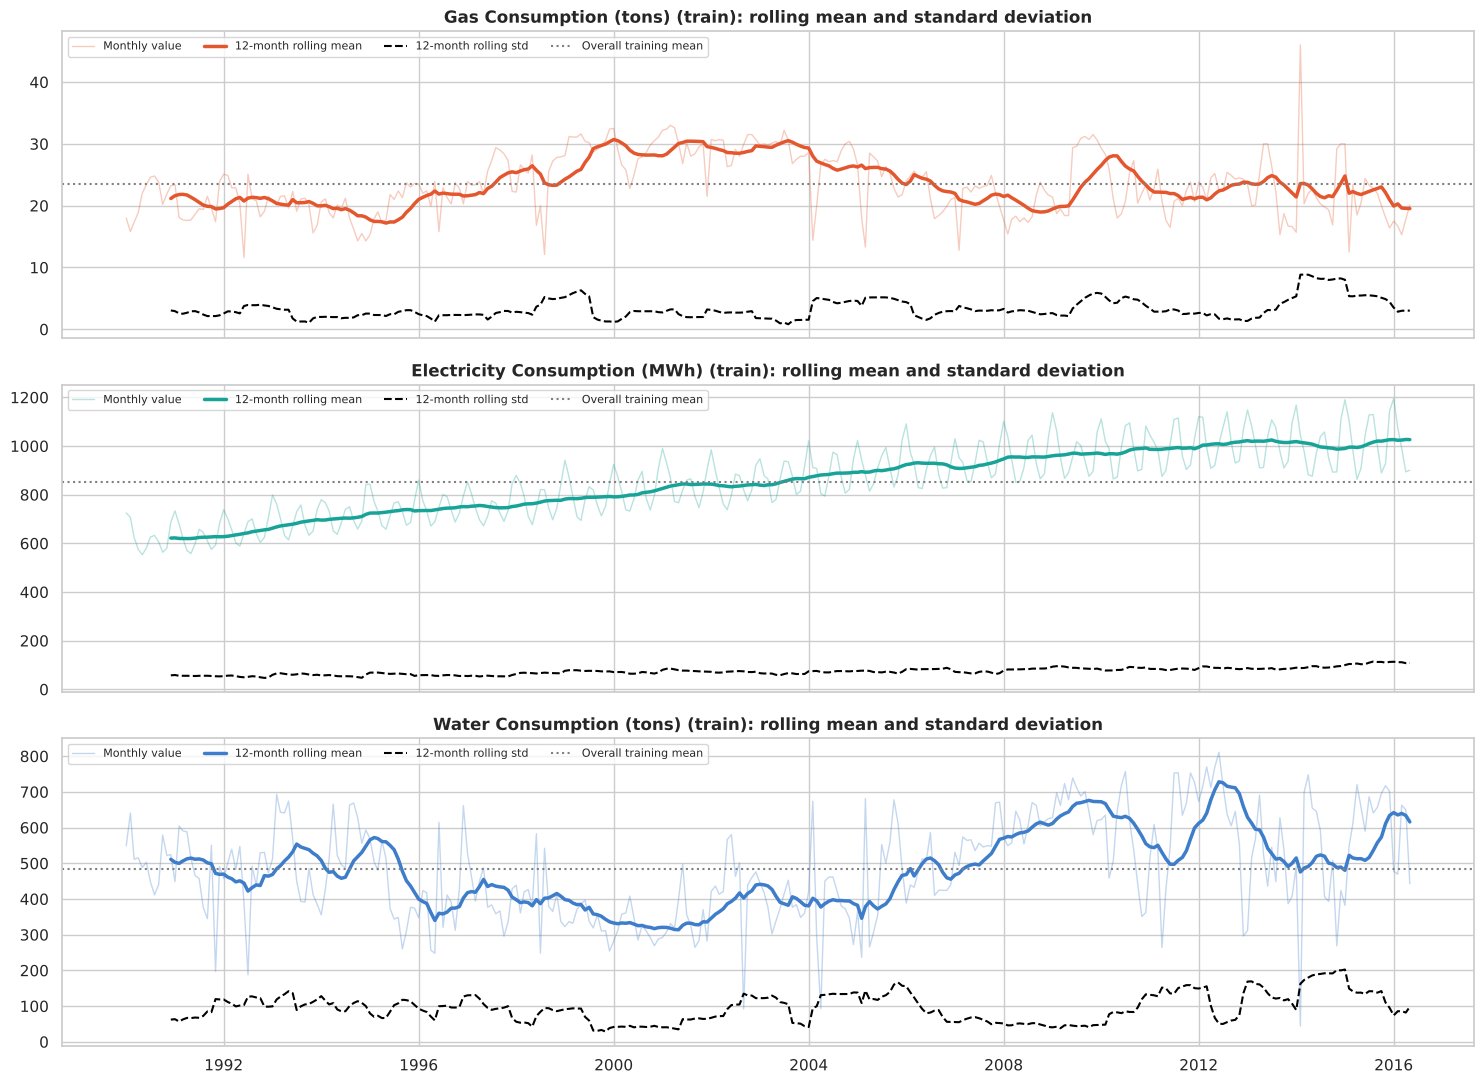

,Rolling mean: first 5 yrs,Rolling mean: last 5 yrs,Rolling mean min,Rolling mean max,Rolling std: first 5 yrs,Rolling std: last 5 yrs
Utility,,,,,,
Gas,19.9,22.3,17.2,30.7,2.6,4.3
Electricity,674.5,1008.5,619.5,1027.0,57.8,93.1
Water,497.5,569.6,313.8,728.3,99.4,134.3


In [12]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
roll_rows = []
for ax, u in zip(axes, UTILITIES):
    s = train[u]
    r_mean, r_std = s.rolling(12).mean(), s.rolling(12).std()
    ax.plot(s.index, s, color=COLORS[u], alpha=0.3, linewidth=1, label="Monthly value")
    ax.plot(s.index, r_mean, color=COLORS[u], linewidth=2.5, label="12-month rolling mean")
    ax.plot(s.index, r_std, color="black", linestyle="--", linewidth=1.5, label="12-month rolling std")
    ax.axhline(s.mean(), color="grey", linestyle=":", linewidth=1.5, label="Overall training mean")
    ax.set_title(f"{u} (train): rolling mean and standard deviation", fontweight="bold")
    ax.legend(loc="upper left", fontsize=8, ncol=4)
    roll_rows.append({"Utility": u.split(" ")[0],
                      "Rolling mean: first 5 yrs": r_mean.iloc[11:71].mean(),
                      "Rolling mean: last 5 yrs": r_mean.iloc[-60:].mean(),
                      "Rolling mean min": r_mean.min(), "Rolling mean max": r_mean.max(),
                      "Rolling std: first 5 yrs": r_std.iloc[11:71].mean(),
                      "Rolling std: last 5 yrs": r_std.iloc[-60:].mean()})
plt.tight_layout()
plt.show()
pd.DataFrame(roll_rows).set_index("Utility").round(1)

**Observations**

- **Gas:** the rolling mean moves in **long waves** between about 17 and 31 tons (for example, it stays near 30 tons from 1999 to 2004), but it **keeps returning to the training average** of about 24 tons. There is no lasting direction: the first five years average 19.9 tons and the last five 22.3 tons. The rolling standard deviation is fairly steady (about 2–5 tons) except for the jump caused by the February 2014 outlier.
- **Electricity:** the rolling mean **climbs steadily** from about 675 MWh in the first five years to about 1,010 MWh in the last five. This is a clear trend, so the series is **non-stationary**. The rolling standard deviation also grows (about 58 → 93 MWh), meaning the seasonal swings get bigger as consumption rises.
- **Water:** the rolling mean wanders widely (about 314–728 tons) but with **no lasting direction**. It falls in the late 1990s, rises to a peak around 2012 and then comes back down towards its average. The rolling standard deviation varies between about 30 and 200 tons.

### Stationarity Results

| Utility | ADF p-value (train) | Rolling statistics | Visual inspection | Decision |
|---|---|---|---|---|
| **Gas** | 0.316 (not stationary) | Mean moves in waves but returns to its average | No lasting trend | **d = 0** |
| **Electricity** | 0.411 (not stationary) | Mean rises steadily | Clear upward trend + yearly cycle | **Seasonal difference D = 1**; extra d tested in Step 6 |
| **Water** | **0.0095** (stationary) | Mean wanders but returns to its average | No lasting trend | **d = 0** |

- **Electricity** is the only utility that clearly needs differencing. A **seasonal difference (D = 1)** compares each month with the same month a year earlier. This removes the 12-month cycle and most of the trend in one step. Whether an extra ordinary difference (d = 1) is *also* needed, or would over-difference the series, is tested in the grid search in Step 6.2.
- **Water** is stationary on all three checks, so **d = 0**.
- **Gas** is the borderline case. The ADF test does not reject non-stationarity (p = 0.316), but the rolling statistics and plots show a level that **keeps coming back** to the same average. The reason they disagree: the ADF test checks for a *random walk*, a series whose level never returns. Gas returns, but slowly, with waves lasting several years. Over a 26-year sample, such slow returns are hard for the test to tell apart from a random walk, so the test is not very reliable here. (On the full series the ADF p-value is 0.011, which is stationary. That includes test data, so it is not used for the decision, but it points the same way.) Differencing gas would throw away the information that its level returns to normal, so **d = 0** is used. Step 6.1 still tests d = 1 as a check.

## Step 5: Baseline Models

Because the utilities behave so differently, **each gets its own set of candidate models**, chosen from the EDA:

| Utility | Pattern | Candidate models |
|---|---|---|
| **Gas** | No long-term growth, weak seasonality | Seasonal Naive, ARIMA(1,0,1), Simple Exponential Smoothing (ETS) |
| **Electricity** | Trend + strong seasonality | Seasonal Naive, SARIMA(0,1,1)(0,1,1)₁₂, Holt-Winters (additive) |
| **Water** | Noisy, no clear pattern | Mean, ARIMA(1,0,1), 12-month Moving Average |

The **Seasonal Naive** (repeat the last 12 months) and **Mean** models act as simple benchmarks. A more complex model is only worth using if it beats them.

**Metrics:**
- **MAE:** average size of the error.
- **RMSE:** like MAE, but penalises large errors more heavily.
- **MAPE:** average percentage error, which allows the three utilities to be compared despite their different units.

In [13]:
def evaluate(actual, predicted, name):
    a, p = np.asarray(actual), np.asarray(predicted)
    return {"Model": name,
            "MAE": mean_absolute_error(a, p),
            "RMSE": np.sqrt(mean_squared_error(a, p)),
            "MAPE (%)": np.mean(np.abs((a - p) / a)) * 100}

def seasonal_naive(train_s, steps):
    return np.tile(train_s[-12:].values, steps // 12 + 1)[:steps]

h = len(val)
tr_gas, va_gas = train[GAS], val[GAS]
tr_elec, va_elec = train[ELEC], val[ELEC]
tr_water, va_water = train[WATER], val[WATER]

gas_df = pd.DataFrame([
    evaluate(va_gas, seasonal_naive(tr_gas, h), "Seasonal Naive"),
    evaluate(va_gas, ARIMA(tr_gas, order=(1, 0, 1)).fit().forecast(h), "ARIMA(1,0,1)"),
    evaluate(va_gas, ExponentialSmoothing(tr_gas, trend=None, seasonal=None).fit().forecast(h), "ETS"),
])
elec_df = pd.DataFrame([
    evaluate(va_elec, seasonal_naive(tr_elec, h), "Seasonal Naive"),
    evaluate(va_elec, SARIMAX(tr_elec, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(h), "SARIMA(0,1,1)(0,1,1,12)"),
    evaluate(va_elec, ExponentialSmoothing(tr_elec, trend="add", seasonal="add", seasonal_periods=12).fit().forecast(h), "Holt-Winters"),
])
water_df = pd.DataFrame([
    evaluate(va_water, np.full(h, tr_water.mean()), "Mean"),
    evaluate(va_water, ARIMA(tr_water, order=(1, 0, 1)).fit().forecast(h), "ARIMA(1,0,1)"),
    evaluate(va_water, np.full(h, tr_water[-12:].mean()), "Moving Average (12)"),
])

for name, d in [("GAS", gas_df), ("ELECTRICITY", elec_df), ("WATER", water_df)]:
    print(f"\n{name} (validation set)")
    print(d.round(2).to_string(index=False))


GAS (validation set)
         Model  MAE  RMSE  MAPE (%)
Seasonal Naive 5.33  6.27     22.53
  ARIMA(1,0,1) 3.21  3.91     15.39
           ETS 5.50  6.27     22.80

ELECTRICITY (validation set)
                  Model   MAE  RMSE  MAPE (%)
         Seasonal Naive 30.57 37.02      2.95
SARIMA(0,1,1)(0,1,1,12) 23.39 29.50      2.22
           Holt-Winters 28.70 34.04      2.77

WATER (validation set)
              Model    MAE   RMSE  MAPE (%)
               Mean  73.32  98.55     19.72
       ARIMA(1,0,1)  71.69  99.11     19.67
Moving Average (12) 142.04 171.63     38.12


### Baseline Results (Validation Set)

| Utility | Best baseline | RMSE | MAPE | Simple benchmark |
|---|---|---|---|---|
| **Gas** | **ARIMA(1,0,1)** | 3.91 | 15.39% | Seasonal Naive: 6.27 / 22.53% |
| **Electricity** | **SARIMA(0,1,1)(0,1,1)₁₂** | 29.50 | 2.22% | Seasonal Naive: 37.02 / 2.95% |
| **Water** | **Mean** | 98.55 | 19.72% | ARIMA(1,0,1): 99.11 / 19.67% |

- **Gas:** ARIMA clearly beats both Seasonal Naive and ETS. ETS performs no better than Seasonal Naive.
- **Electricity:** SARIMA is the most accurate, ahead of Holt-Winters (34.04) and Seasonal Naive. Even the simple Seasonal Naive model is accurate (2.95%), which shows how strong and regular electricity's seasonal pattern is.
- **Water:** **no model beats simply predicting the training average.** ARIMA(1,0,1) is essentially equal to the Mean, and the 12-month Moving Average is much worse (38% MAPE). This fits the EDA finding that water's history contains very little usable pattern. Because this is based on one window only, Step 6 re-checks it over four validation windows.

## Step 6: Hyperparameter Tuning (Rolling-Origin Validation)

Step 5 scored every model on **one** 39-month window (June 2016 – August 2019). One window is a small sample: a model can win just because it suits those particular three years.

Here, every configuration is scored on **four validation windows**, two years apart. For each window, the model is trained on all months before it and then forecasts the next 39 months, exactly the way it will be used in practice. The four errors are then **averaged**. The last window is the original validation set, and all four end before the test period (September 2019), so the **test set stays completely unseen**.

**Selection rule:** the lowest average validation RMSE wins. If several configurations are within **1%** of the best, the one with the **fewest AR/MA terms** is chosen. Differences that small are within noise, and a simpler model is less likely to overfit and easier to explain.

In [14]:
trval = pd.concat([train, val])   # every month before the test period
N_FOLDS, STEP = 4, 24             # 4 validation windows, 2 years apart
fold_ends = [len(trval) - h - STEP * k for k in range(N_FOLDS - 1, -1, -1)]

def rolling_cv(series, forecast_fn):
    """Fit on everything before each window, forecast the next h months, and average the errors."""
    rmses, mapes = [], []
    for end in fold_ends:
        tr_s, va_s = series.iloc[:end], series.iloc[end:end + h]
        r = evaluate(va_s, forecast_fn(tr_s, len(va_s)), "")
        rmses.append(r["RMSE"]); mapes.append(r["MAPE (%)"])
    return {"CV RMSE": np.mean(rmses), "CV MAPE (%)": np.mean(mapes), "Fold RMSEs": np.round(rmses, 2)}

pd.DataFrame({
    "Train on": [f"Jan 1990 – {trval.index[e - 1]:%b %Y}" for e in fold_ends],
    "Validate on": [f"{trval.index[e]:%b %Y} – {trval.index[e + h - 1]:%b %Y}" for e in fold_ends],
}, index=[f"Window {i + 1}" for i in range(N_FOLDS)])

,Train on,Validate on
Window 1,Jan 1990 – May 2010,Jun 2010 – Aug 2013
Window 2,Jan 1990 – May 2012,Jun 2012 – Aug 2015
Window 3,Jan 1990 – May 2014,Jun 2014 – Aug 2017
Window 4,Jan 1990 – May 2016,Jun 2016 – Aug 2019


In [15]:
def n_params(cfg):
    """Number of AR/MA terms in a configuration (used to prefer simpler models)."""
    if isinstance(cfg[0], tuple):
        (p, d, q), (P, D, Q, m) = cfg
        return p + q + P + Q
    p, d, q = cfg
    return p + q

def grid_search(series, fit_forecast, configs):
    rows = []
    for cfg in configs:
        try:
            d = cfg[0][1] if isinstance(cfg[0], tuple) else cfg[1]
            name = f"SARIMA{cfg[0]}{cfg[1]}" if isinstance(cfg[0], tuple) else f"ARIMA{cfg}"
            rows.append({"Model": name, "cfg": cfg, "d": d, "Params": n_params(cfg),
                         **rolling_cv(series, lambda s, k: fit_forecast(s, k, cfg))})
        except Exception:
            pass
    g = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
    # Differences under 1% are within noise, so among those pick the simplest model
    near_best = g[g["CV RMSE"] <= g.loc[0, "CV RMSE"] * 1.01]
    chosen = near_best.sort_values(["Params", "CV RMSE"]).iloc[0]
    return g, chosen

def show_grid(g, chosen, label):
    print(f"Top 5 {label} configurations (average over 4 validation windows):")
    print(g.drop(columns=["cfg"]).head().round(2).to_string(index=False))
    print("\nBest configuration for each amount of differencing:")
    print(g.groupby("d").first()[["Model", "CV RMSE", "CV MAPE (%)"]].round(2).to_string())
    print(f"\nChosen: {chosen['Model']}  (CV RMSE {chosen['CV RMSE']:.2f}, {chosen['Params']} AR/MA terms)")

### 6.1 Gas: ARIMA(p, d, q)

The EDA and rolling statistics say gas should not be differenced. **d = 1** is included in the grid only as a check: if differencing were really needed, it would win here.

In [16]:
gas_configs = [(p, d, q) for d in (0, 1) for p in range(4) for q in range(4) if (p, q) != (0, 0)]
gas_grid, gas_best = grid_search(trval[GAS], lambda s, k, o: ARIMA(s, order=o).fit().forecast(k), gas_configs)
best_gas_order = gas_best["cfg"]
show_grid(gas_grid, gas_best, "gas")

Top 5 gas configurations (average over 4 validation windows):
         Model  d  Params  CV RMSE  CV MAPE (%)               Fold RMSEs
ARIMA(1, 0, 2)  0       3     4.47        17.31   [2.8, 5.7, 5.41, 3.96]
ARIMA(1, 0, 1)  0       2     4.47        17.55 [2.84, 5.71, 5.43, 3.91]
ARIMA(3, 0, 0)  0       3     4.50        17.65  [2.85, 5.7, 5.43, 3.99]
ARIMA(2, 0, 0)  0       2     4.52        17.79 [2.87, 5.71, 5.45, 4.05]
ARIMA(3, 0, 1)  0       4     4.57        17.51 [2.88, 5.65, 5.19, 4.54]

Best configuration for each amount of differencing:
            Model  CV RMSE  CV MAPE (%)
d                                      
0  ARIMA(1, 0, 2)     4.47        17.31
1  ARIMA(2, 1, 1)     4.72        18.02

Chosen: ARIMA(1, 0, 1)  (CV RMSE 4.47, 2 AR/MA terms)


**Gas result**

- The top configurations are almost identical (average RMSE 4.47–4.52). ARIMA(1,0,2) and ARIMA(1,0,1) tie at 4.47, so the selection rule picks the simpler **ARIMA(1,0,1)**, the same model as the baseline.
- The best **d = 1** model, ARIMA(2,1,1), scores 4.72, which is **5.6% worse**. This confirms the decision in Step 4: gas should **not** be differenced. Differencing throws away the fact that gas returns to its usual level, and the forecasts get worse.

### 6.2 Electricity: SARIMA(p, d, q)(P, 1, Q)₁₂

Electricity clearly needs differencing. The question is **how much**. The seasonal difference (D = 1) is kept because of the strong yearly cycle. The grid tests whether an extra ordinary difference (**d = 1**) is also needed or whether it **over-differences** the series.

In [17]:
elec_configs = [((p, d, q), (P, 1, Q, 12)) for d in (0, 1) for p in range(3) for q in range(3)
                for P in range(2) for Q in range(2) if (p, q) != (0, 0) and (P, Q) != (0, 0)]
elec_grid, elec_best = grid_search(
    trval[ELEC], lambda s, k, c: SARIMAX(s, order=c[0], seasonal_order=c[1]).fit(disp=False).forecast(k), elec_configs)
best_elec_order, best_elec_seasonal = elec_best["cfg"]
show_grid(elec_grid, elec_best, "electricity")

Top 5 electricity configurations (average over 4 validation windows):
                       Model  d  Params  CV RMSE  CV MAPE (%)                   Fold RMSEs
SARIMA(1, 0, 2)(1, 1, 1, 12)  0       5    35.87         2.82 [34.23, 43.38, 33.89, 31.96]
SARIMA(1, 0, 2)(0, 1, 1, 12)  0       4    35.95         2.83 [34.55, 43.41, 33.89, 31.95]
SARIMA(0, 1, 2)(1, 1, 1, 12)  1       4    36.20         2.88  [33.12, 44.1, 34.88, 32.69]
SARIMA(0, 1, 2)(0, 1, 1, 12)  1       3    36.26         2.89 [33.36, 44.12, 34.88, 32.68]
SARIMA(2, 0, 2)(0, 1, 1, 12)  0       5    38.02         3.12 [32.24, 46.36, 40.42, 33.06]

Best configuration for each amount of differencing:
                          Model  CV RMSE  CV MAPE (%)
d                                                    
0  SARIMA(1, 0, 2)(1, 1, 1, 12)    35.87         2.82
1  SARIMA(0, 1, 2)(1, 1, 1, 12)    36.20         2.88

Chosen: SARIMA(1, 0, 2)(0, 1, 1, 12)  (CV RMSE 35.95, 4 AR/MA terms)


**Electricity result**

- The best model **without** an extra difference (**d = 0**) scores 35.87, slightly better than the best model **with** one (**d = 1**, 36.20).
- The top two configurations are within 1% of each other: SARIMA(1,0,2)(1,1,1)₁₂ (35.87, 5 terms) and SARIMA(1,0,2)(0,1,1)₁₂ (35.95, 4 terms). The selection rule chooses the simpler **SARIMA(1,0,2)(0,1,1)₁₂**.
- **Why d = 0 works:** the seasonal difference already compares each month with the same month last year, which removes most of the trend. Adding d = 1 on top differences the series **twice**, which risks over-differencing. The fitted AR coefficient is 0.998, very close to 1, so the model can still follow slow changes in level without being forced to extend the old growth.
- **Why four windows matter:** on the original single window (window 4) alone, SARIMA(0,1,1)(1,1,1)₁₂ with d = 1 scores best (RMSE 29.47). Averaged over all four windows it scores 39.98, which is **11% worse** than the chosen model. It only looked best because it happened to suit 2016–2019.

### 6.3 Water: ARIMA(p, d, q) vs the Mean benchmark

In Step 5 the **Mean** was the best water baseline, so the tuned model is compared against the Mean on the same four windows.

In [18]:
water_configs = [(p, d, q) for d in (0, 1) for p in range(4) for q in range(4) if (p, q) != (0, 0)]
water_grid, water_best = grid_search(trval[WATER], lambda s, k, o: ARIMA(s, order=o).fit().forecast(k), water_configs)
best_water_order = water_best["cfg"]
water_mean_cv = rolling_cv(trval[WATER], lambda s, k: np.full(k, s.mean()))
show_grid(water_grid, water_best, "water")
print(f"\nMean benchmark: CV RMSE {water_mean_cv['CV RMSE']:.2f}, CV MAPE {water_mean_cv['CV MAPE (%)']:.2f}%, folds {water_mean_cv['Fold RMSEs']}")

Top 5 water configurations (average over 4 validation windows):
         Model  d  Params  CV RMSE  CV MAPE (%)                       Fold RMSEs
ARIMA(1, 0, 1)  0       2   139.81        30.42  [171.27, 154.82, 134.02, 99.11]
ARIMA(2, 0, 2)  0       4   140.52        32.86   [147.7, 169.92, 128.6, 115.87]
ARIMA(1, 0, 2)  0       3   141.01        32.15   [158.79, 170.1, 130.05, 105.1]
ARIMA(2, 0, 3)  0       5   141.45        32.92 [150.25, 170.95, 129.25, 115.35]
ARIMA(3, 0, 3)  0       6   141.60        32.91 [150.76, 170.91, 128.67, 116.07]

Best configuration for each amount of differencing:
            Model  CV RMSE  CV MAPE (%)
d                                      
0  ARIMA(1, 0, 1)   139.81        30.42
1  ARIMA(1, 1, 3)   153.21        36.89

Chosen: ARIMA(1, 0, 1)  (CV RMSE 139.81, 2 AR/MA terms)

Mean benchmark: CV RMSE 149.98, CV MAPE 30.09%, folds [195.3  166.89 139.17  98.55]


**Water result**

- **ARIMA(1,0,1)** has the lowest average error (139.81) and beats the **Mean** benchmark (149.98) by **6.8%**.
- Window by window, ARIMA clearly wins in windows 1 and 2, is slightly ahead in window 3, and is **slightly behind** in window 4 (99.11 vs 98.55). Window 4 is the only window Step 5 looked at, which is why the Mean seemed best there. Over a longer history, ARIMA does capture some useful short-term pattern.
- Every **d = 1** model is worse (best 153.21), which confirms that water should not be differenced.
- An average validation MAPE of about 30% shows that water is still **hard to forecast**.

In [19]:
baseline_cv = {
    "Gas": ("ARIMA(1,0,1)", rolling_cv(trval[GAS], lambda s, k: ARIMA(s, order=(1, 0, 1)).fit().forecast(k))),
    "Electricity": ("SARIMA(0,1,1)(0,1,1,12)", rolling_cv(trval[ELEC], lambda s, k: SARIMAX(
        s, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(k))),
    "Water": ("Mean", water_mean_cv),
}
tuned = {"Gas": gas_best, "Electricity": elec_best, "Water": water_best}
tuning_df = pd.DataFrame([{
    "Utility": u, "Best baseline": b_name, "Baseline CV RMSE": b["CV RMSE"],
    "Tuned model": tuned[u]["Model"], "Tuned CV RMSE": tuned[u]["CV RMSE"], "Tuned CV MAPE (%)": tuned[u]["CV MAPE (%)"],
} for u, (b_name, b) in baseline_cv.items()])
tuning_df["RMSE change (%)"] = (tuning_df["Baseline CV RMSE"] - tuning_df["Tuned CV RMSE"]) / tuning_df["Baseline CV RMSE"] * 100
tuning_df.round(2)

,Utility,Best baseline,Baseline CV RMSE,Tuned model,Tuned CV RMSE,Tuned CV MAPE (%),RMSE change (%)
0,Gas,"ARIMA(1,0,1)",4.47,"ARIMA(1, 0, 1)",4.47,17.55,0.00
1,Electricity,"SARIMA(0,1,1)(0,1,1,12)",40.01,"SARIMA(1, 0, 2)(0, 1, 1, 12)",35.95,2.83,10.14
2,Water,Mean,149.98,"ARIMA(1, 0, 1)",139.81,30.42,6.78


### Tuning Results (average over the four validation windows)

| Utility | Best baseline (Step 5) | Baseline RMSE | Tuned model | Tuned RMSE | Improvement |
|---|---|---|---|---|---|
| **Gas** | ARIMA(1,0,1) | 4.47 | **ARIMA(1,0,1)** | 4.47 | 0% |
| **Electricity** | SARIMA(0,1,1)(0,1,1)₁₂ | 40.01 | **SARIMA(1,0,2)(0,1,1)₁₂** | 35.95 | **10.1%** |
| **Water** | Mean | 149.98 | **ARIMA(1,0,1)** | 139.81 | **6.8%** |

- **Gas:** the baseline was already the best choice.
- **Electricity:** the improvement comes mainly from **removing the extra ordinary difference** (d = 1 → d = 0), i.e. getting the amount of differencing right, rather than from fine-tuning p and q.
- **Water:** the tuned model is compared with the **Mean**, its actual best baseline from Step 5, and beats it on average.

## Step 7: Final Evaluation on the Test Set

Each chosen model is **retrained on train + validation** (all data before September 2019), then evaluated **once** on the unseen test period (**September 2019 – January 2023**). The test set played no part in choosing any model.

In [20]:
ht = len(test)
final_specs = {
    GAS:   ("ARIMA" + str(best_gas_order), lambda s: ARIMA(s, order=best_gas_order).fit()),
    ELEC:  (f"SARIMA{best_elec_order}{best_elec_seasonal}", lambda s: SARIMAX(s, order=best_elec_order, seasonal_order=best_elec_seasonal).fit(disp=False)),
    WATER: ("ARIMA" + str(best_water_order), lambda s: ARIMA(s, order=best_water_order).fit()),
}
cv_best = {GAS: gas_best, ELEC: elec_best, WATER: water_best}

fitted, test_forecasts, rows = {}, {}, []
for u, (name, fit) in final_specs.items():
    fitted[u] = fit(trval[u])
    fc = fitted[u].forecast(ht)
    test_forecasts[u] = fc
    r = evaluate(test[u], fc, name)
    rows.append({"Utility": u.split(" ")[0], "Model": name,
                 "CV RMSE": cv_best[u]["CV RMSE"], "CV MAPE (%)": cv_best[u]["CV MAPE (%)"],
                 "Test MAE": r["MAE"], "Test RMSE": r["RMSE"], "Test MAPE (%)": r["MAPE (%)"],
                 "Bias (mean error)": float(np.mean(test[u].values - fc.values)),
                 "Converged": fitted[u].mle_retvals.get("converged")})
final_df = pd.DataFrame(rows)
final_df.round(2)

,Utility,Model,CV RMSE,CV MAPE (%),Test MAE,Test RMSE,Test MAPE (%),Bias (mean error),Converged
0,Gas,"ARIMA(1, 0, 1)",4.47,17.55,4.16,5.06,15.03,3.39,True
1,Electricity,"SARIMA(1, 0, 2)(0, 1, 1, 12)",35.95,2.83,27.06,36.76,2.61,-7.59,True
2,Water,"ARIMA(1, 0, 1)",139.81,30.42,85.20,106.38,17.77,19.72,True


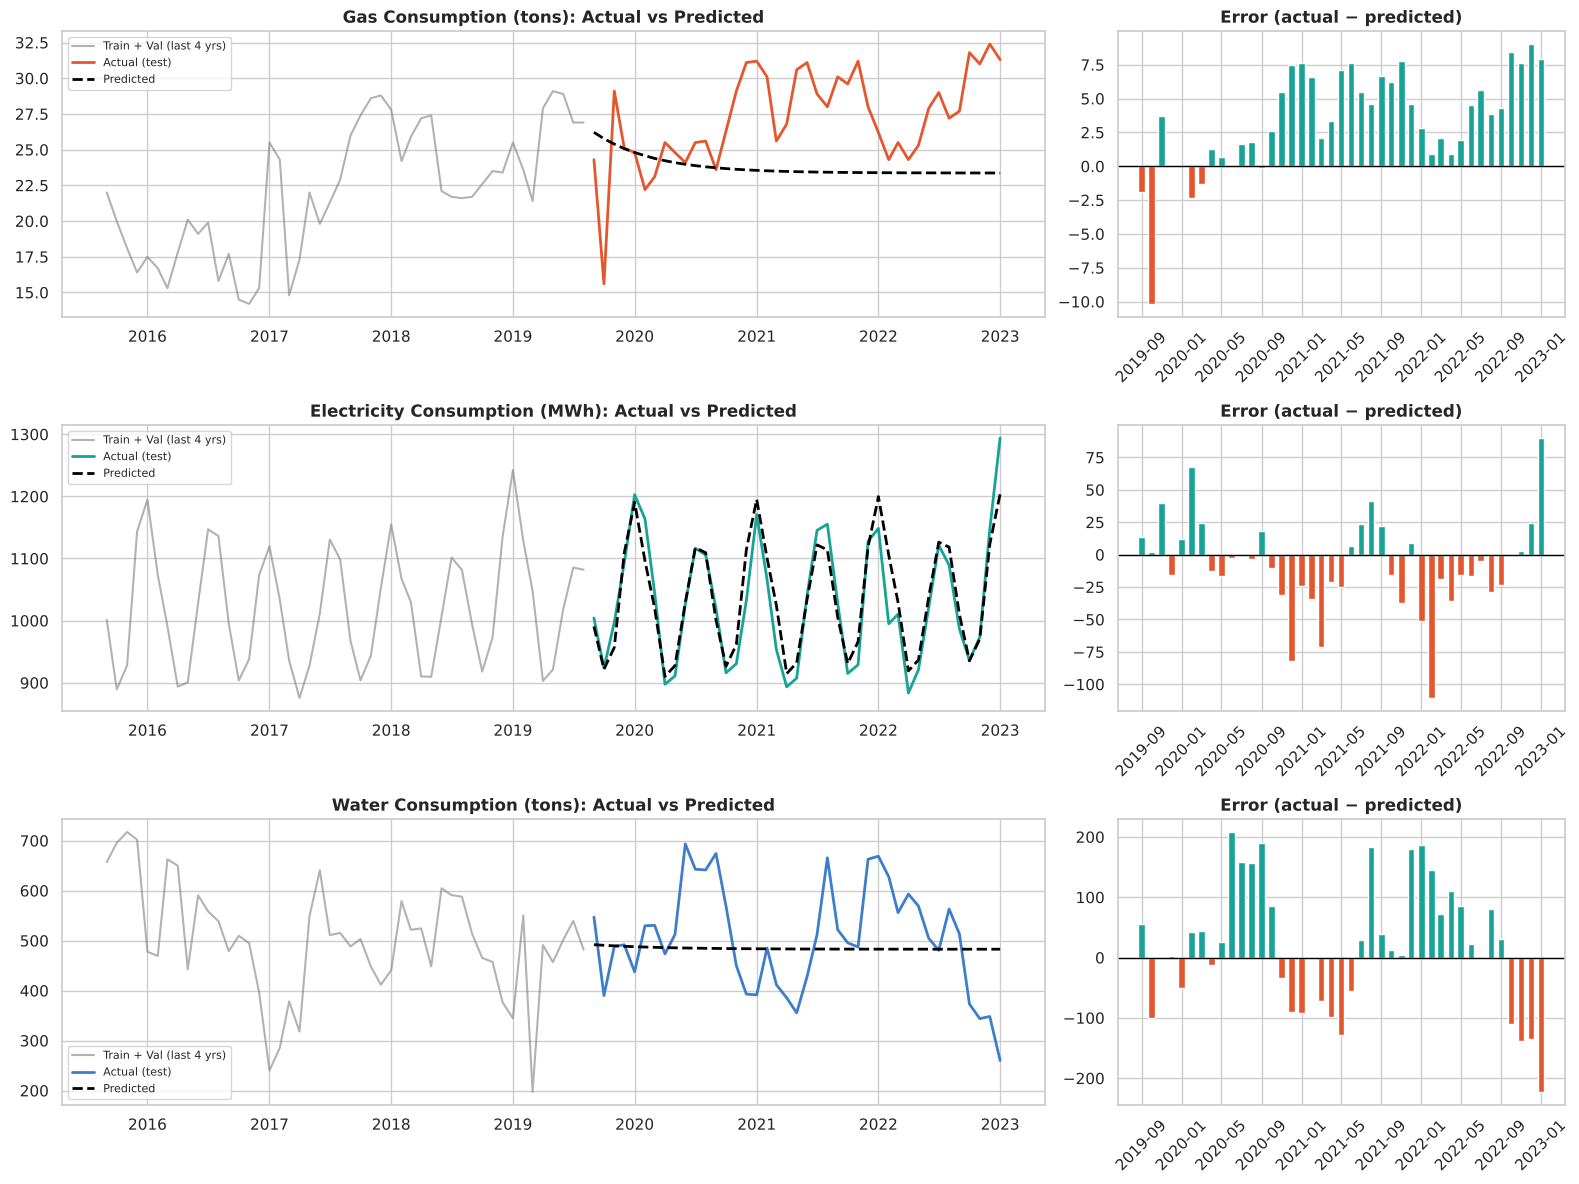

In [21]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12), gridspec_kw={"width_ratios": [2.2, 1]})
for i, u in enumerate(UTILITIES):
    axes[i, 0].plot(trval[u].iloc[-48:].index, trval[u].iloc[-48:], color="grey", alpha=0.6, label="Train + Val (last 4 yrs)")
    axes[i, 0].plot(test.index, test[u], color=COLORS[u], linewidth=2, label="Actual (test)")
    axes[i, 0].plot(test.index, test_forecasts[u], color="black", linestyle="--", linewidth=2, label="Predicted")
    axes[i, 0].set_title(f"{u}: Actual vs Predicted", fontweight="bold"); axes[i, 0].legend(fontsize=8)
    err = test[u].values - test_forecasts[u].values
    axes[i, 1].bar(test.index, err, width=20, color=np.where(err >= 0, "#17A398", "#E4572E"))
    axes[i, 1].axhline(0, color="black", linewidth=1)
    axes[i, 1].set_title("Error (actual − predicted)", fontweight="bold")
    axes[i, 1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Test Set Results

| Utility | Final model | Validation MAPE (4-window avg) | **Test MAPE** | Test RMSE | Bias (actual − predicted) |
|---|---|---|---|---|---|
| **Gas** | ARIMA(1,0,1) | 17.55% | **15.03%** | 5.06 | +3.39 tons |
| **Electricity** | SARIMA(1,0,2)(0,1,1)₁₂ | 2.83% | **2.61%** | 36.76 | −7.59 MWh |
| **Water** | ARIMA(1,0,1) | 30.42% | **17.77%** | 106.38 | +19.72 tons |

All three final models **converged** (see the `Converged` column). A positive bias means actual use was, on average, higher than predicted.

- **Electricity** is forecast very accurately (**2.6% MAPE**) with almost **no bias** (−7.6 MWh on a level of about 1,000 MWh). The errors switch between positive and negative rather than staying on one side. The largest misses are **February 2022** (about −110 MWh, over-predicted) and **January 2023** (about +90 MWh, when consumption hit a record 1,294 MWh).
- **Gas** settles at about **23.4 tons**, while actual use **rose to 28–32 tons in 2021–2022**. **Every error from October 2020 onwards is positive.** This is a shift in level that the model cannot anticipate, because it always pulls back towards the long-run average. Differencing would not fix this: d = 1 was worse in validation (Step 6.1). It most likely reflects an outside change in how the building uses gas.
- **Water** forecasts are essentially a **flat line at about 485–490 tons**. Actual use swings between about 260 and 695 tons, with long runs of positive and negative errors. **Monthly water use is mostly unpredictable** from its own history.
- **Generalisation:** electricity's test error (2.6%) matches its validation error (2.8%), and gas is similar (17.6% → 15.0%). Water's test MAPE is much lower than its validation average (30.4% → 17.8%) because the early validation windows include the very volatile 2010–2015 period. The test period was simply calmer, not more predictable.

### 7.1 Residual Analysis

A good model should leave behind only **random noise**. If the residuals (actual − fitted, on the train + validation data) are still correlated with their own past values, the model has missed a pattern it could have used.

- **Residual ACF:** bars outside the blue band are significant autocorrelations.
- **Ljung-Box test:** checks the first 12 and 24 lags together. **p ≥ 0.05** means no significant autocorrelation is left, so the residuals look like white noise.

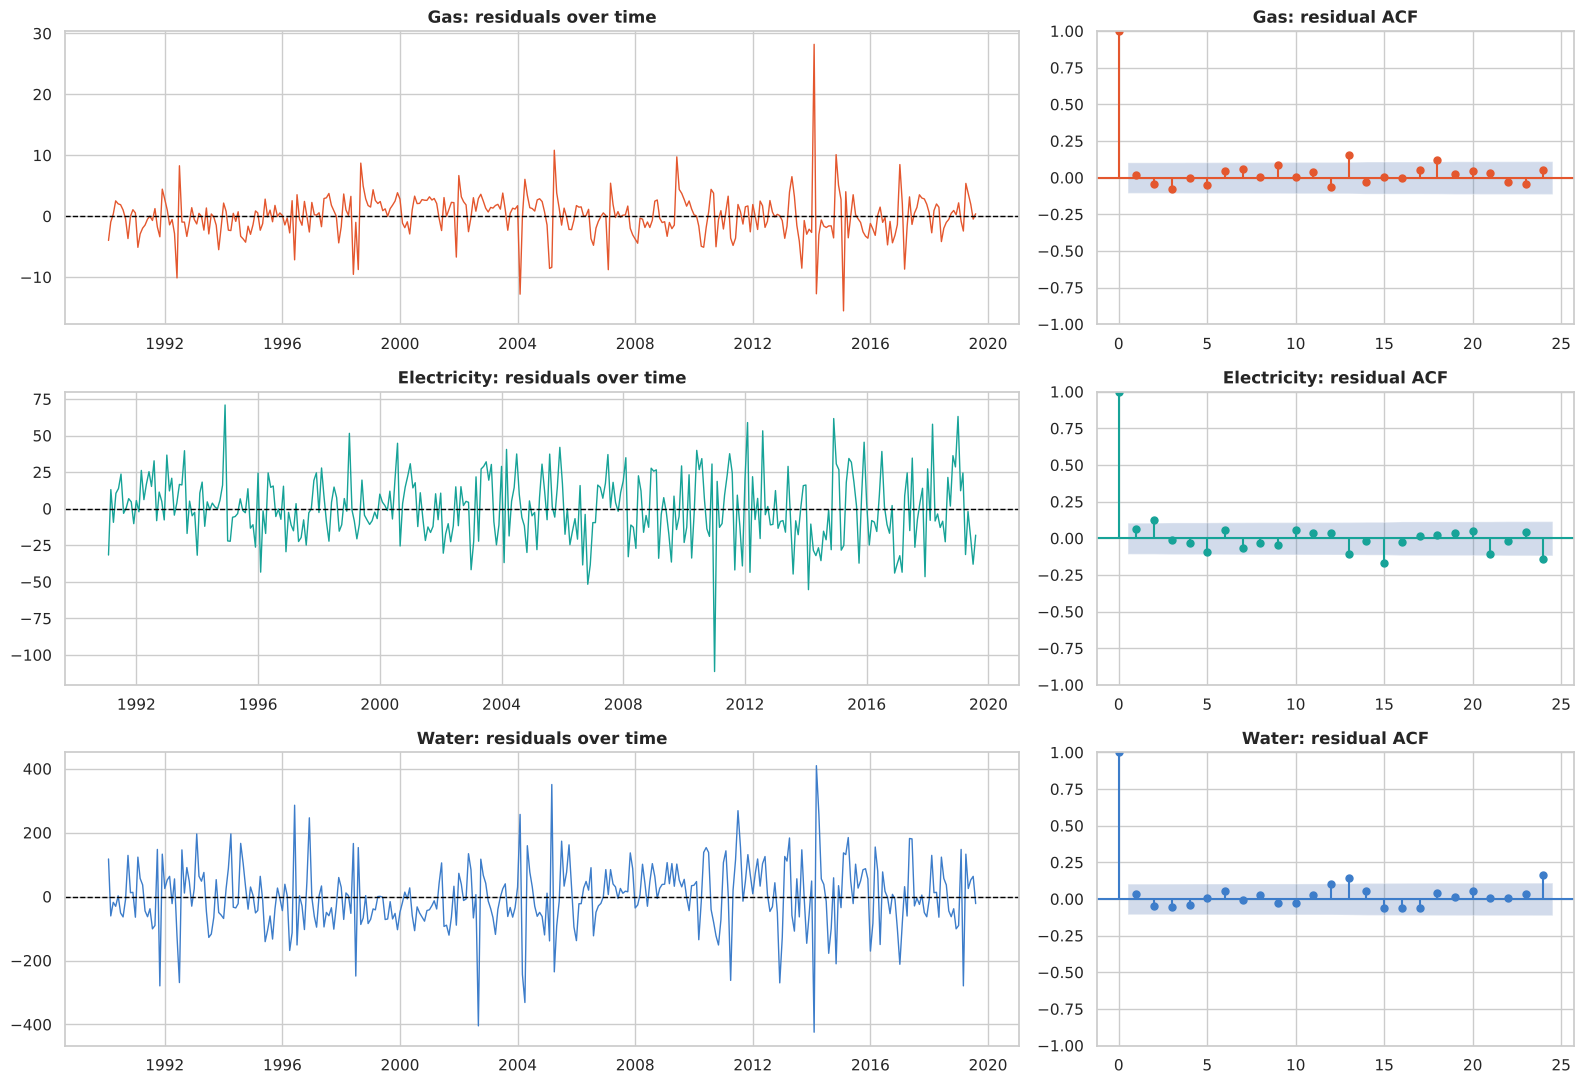

,Model,Ljung-Box p (12 lags),Ljung-Box p (24 lags),White noise? (12 lags),White noise? (24 lags),Residual mean
Utility,,,,,,
Gas,"ARIMA(1, 0, 1)",0.5552,0.2128,Yes,Yes,0.0378
Electricity,"SARIMA(1, 0, 2)(0, 1, 1, 12)",0.1806,0.0054,Yes,No,0.2710
Water,"ARIMA(1, 0, 1)",0.6689,0.0723,Yes,Yes,-0.2290


In [22]:
fig, axes = plt.subplots(3, 2, figsize=(16, 11), gridspec_kw={"width_ratios": [2, 1]})
lb_rows = []
for i, u in enumerate(UTILITIES):
    short = u.split(" ")[0]
    burn = 13 if u == ELEC else 1   # skip the start-up residuals created by (seasonal) differencing
    resid = fitted[u].resid.iloc[burn:]
    axes[i, 0].plot(resid.index, resid, color=COLORS[u], linewidth=1)
    axes[i, 0].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[i, 0].set_title(f"{short}: residuals over time", fontweight="bold")
    plot_acf(resid, lags=24, ax=axes[i, 1], color=COLORS[u], vlines_kwargs={"colors": COLORS[u]})
    axes[i, 1].set_title(f"{short}: residual ACF", fontweight="bold")
    lb = acorr_ljungbox(resid, lags=[12, 24], return_df=True)
    lb_rows.append({"Utility": short, "Model": final_specs[u][0],
                    "Ljung-Box p (12 lags)": lb.loc[12, "lb_pvalue"], "Ljung-Box p (24 lags)": lb.loc[24, "lb_pvalue"],
                    "White noise? (12 lags)": "Yes" if lb.loc[12, "lb_pvalue"] >= 0.05 else "No",
                    "White noise? (24 lags)": "Yes" if lb.loc[24, "lb_pvalue"] >= 0.05 else "No",
                    "Residual mean": resid.mean()})
plt.tight_layout()
plt.show()
pd.DataFrame(lb_rows).set_index("Utility").round(4)

### Residual Analysis Results

| Utility | Ljung-Box p (12 lags) | Ljung-Box p (24 lags) | Verdict |
|---|---|---|---|
| **Gas** | 0.555 | 0.213 | White noise ✔ |
| **Electricity** | 0.181 | **0.005** | Small leftover pattern at longer lags |
| **Water** | 0.669 | 0.072 | White noise ✔ (borderline at 24 lags) |

- **Gas:** no significant autocorrelation left, and the residuals are centred on zero. The single large spike is the **February 2014** outlier. The model has used all the pattern available in gas's own history.
- **Electricity:** no leftover pattern over the first 12 lags, but a small amount at **lags 2, 15 and 24** (correlations of about 0.12–0.17, so weak). Lag 24 means two years back, which suggests the **seasonal pattern slowly changes** over time. This matches the rolling statistics: the seasonal swings grow as consumption grows. A **log transform**, which turns growing swings into constant ones, is a possible improvement.
- **Water:** passes both tests. There are weak spikes at lags 12, 13 and 24 (about 0.10–0.16), i.e. a faint yearly pattern. Step 9.1 shows that adding seasonal terms does not improve validation accuracy, so this pattern is too weak to forecast with.

**Important:** residuals that look like white noise mean a model has used everything in its **own past**. They do **not** guarantee good forecasts. Gas passes the residual test but still under-predicts the test period, because no model based only on gas's history could have predicted the 2020–2022 rise in level.

## Step 8: 60-Month Forecast

Each final model is **retrained on the full dataset** (January 1990 – January 2023) and used to forecast the **next 60 months**, with **95% confidence intervals**.

Gas: ARIMA(1, 0, 1) refitted on all data, converged = True


Electricity: SARIMA(1, 0, 2)(0, 1, 1, 12) refitted on all data, converged = True
Water: ARIMA(1, 0, 1) refitted on all data, converged = True


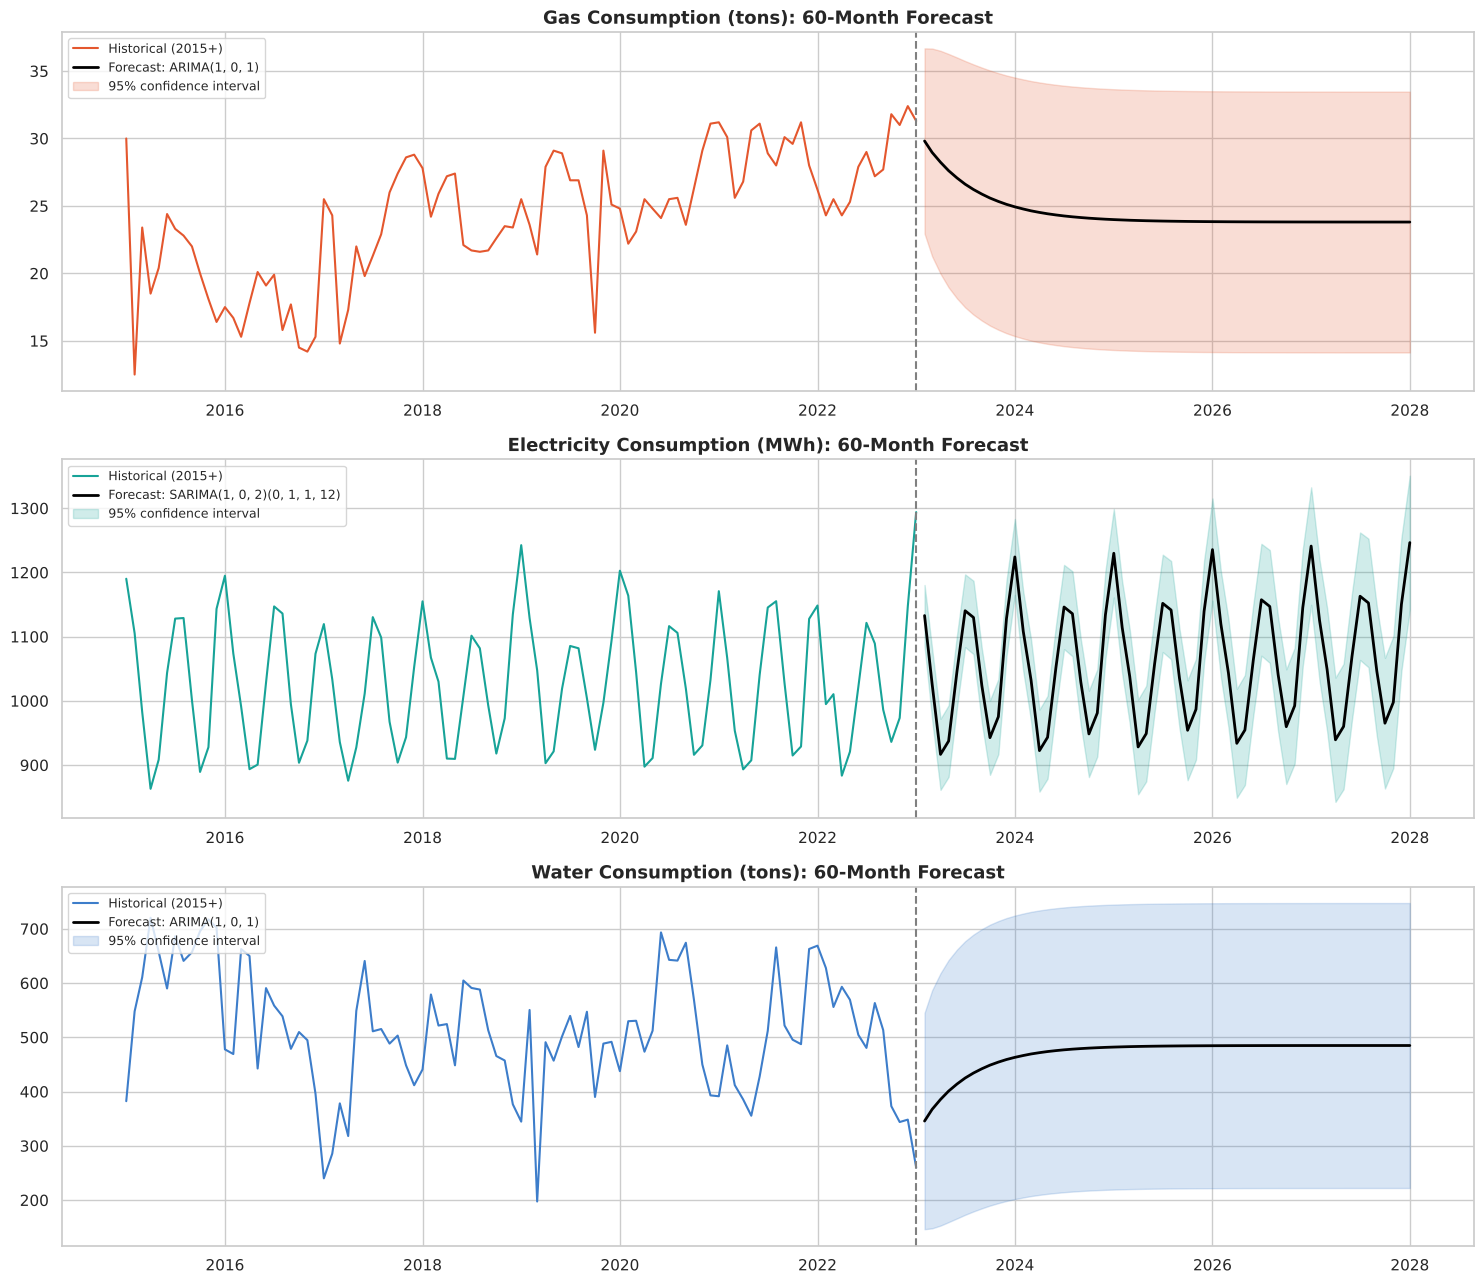

Forecast period: Feb 2023 – Jan 2028


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
Year (avg per month),,,
2023,26.9,1036.3,416.1
2024,24.4,1054.8,474.7
2025,23.9,1060.5,483.6
2026,23.8,1066.1,484.7
2027,23.8,1071.6,484.9
2028,23.8,1246.5,484.9


In [23]:
H = 60
forecast_rows = {}
fig, axes = plt.subplots(3, 1, figsize=(15, 13))
for ax, u in zip(axes, UTILITIES):
    name, fit = final_specs[u]
    model = fit(df[u])
    print(f"{u.split(' ')[0]}: {name} refitted on all data, converged = {model.mle_retvals.get('converged')}")
    res = model.get_forecast(H)
    mean, ci = res.predicted_mean, res.conf_int(alpha=0.05)
    forecast_rows[u] = mean
    hist = df[u].loc["2015":]
    ax.plot(hist.index, hist, color=COLORS[u], linewidth=1.5, label="Historical (2015+)")
    ax.plot(mean.index, mean, color="black", linewidth=2, label=f"Forecast: {name}")
    ax.fill_between(mean.index, ci.iloc[:, 0], ci.iloc[:, 1], color=COLORS[u], alpha=0.2, label="95% confidence interval")
    ax.axvline(df.index[-1], color="grey", linestyle="--")
    ax.set_title(f"{u}: 60-Month Forecast", fontsize=13, fontweight="bold"); ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

forecast_df = pd.DataFrame(forecast_rows)
print(f"Forecast period: {forecast_df.index.min():%b %Y} – {forecast_df.index.max():%b %Y}")
yearly = forecast_df.groupby(forecast_df.index.year).mean().round(1)
yearly.index.name = "Year (avg per month)"
yearly

### Forecast Interpretation (February 2023 – January 2028)

| Year | Gas (tons/month) | Electricity (MWh/month) | Water (tons/month) |
|---|---|---|---|
| 2023 (Feb–Dec) | 26.9 | 1,036 | 416 |
| 2024 | 24.4 | 1,055 | 475 |
| 2025 | 23.9 | 1,061 | 484 |
| 2026 | 23.8 | 1,066 | 485 |
| 2027 | 23.8 | 1,072 | 485 |

*2028 only contains January, a seasonal peak month, so its average (1,247 MWh) is not comparable and is left out.*

- **Electricity** keeps its strong seasonal pattern, with January peaks of about **1,224 MWh (2024) to 1,247 MWh (2028)**. Average use grows only slowly, about **0.5% per year** (1,055 → 1,072 MWh per month). This matches the history: the trend has been nearly flat since about 2013, and 2022 averaged 1,019 MWh. The 95% confidence band roughly doubles in width over the five years.
- **Gas** starts near its recent level (about 30 tons) and **returns to its long-run average of about 23.8 tons** within about two years. By 2028 the 95% interval is **14.1–33.5 tons**. The last 12 months averaged 28.1 tons, which is inside the band but above the central forecast.
- **Water** starts low (about 346 tons, because the last few months were low) and rises back to its **average of about 485 tons**, with a very wide band (**222–748 tons**).

**Why the gas and water forecasts flatten out:** both are stationary (d = 0) with no seasonal terms. Each month ahead, the forecast moves a fixed share closer to the long-run average. The AR coefficients (from the full-data refit) are 0.86 for gas and 0.85 for water, so about 15% of the remaining gap closes each month. Random month-to-month swings cannot be predicted, since they are equally likely to go up or down, so they appear in the **confidence band**, not in the forecast line. Seasonal terms were tested (Step 9.1) and did not improve accuracy, so there is no reliable pattern to project.

**Planning implications**
1. **Electricity:** budget for roughly flat average use, with seasonal peaks of about **1,225–1,250 MWh in January**. Use the upper confidence band for capacity planning.
2. **Gas:** use about 24 tons as the central long-run estimate, but recent use has been about **28 tons**. Refit the model every quarter. If the higher level persists, the long-run average itself has shifted.
3. **Water:** treat 485 tons as a rough average and budget using the confidence range. The bigger opportunity is to **investigate and control** what causes the large swings.

### 8.1 What Do Possible Futures Look Like?

The gas and water forecast lines are flat, while the real data zigzags. To show why, the final gas and water models are used to **simulate three possible futures**. Each one adds random month-to-month swings of the same size the model saw in the history.

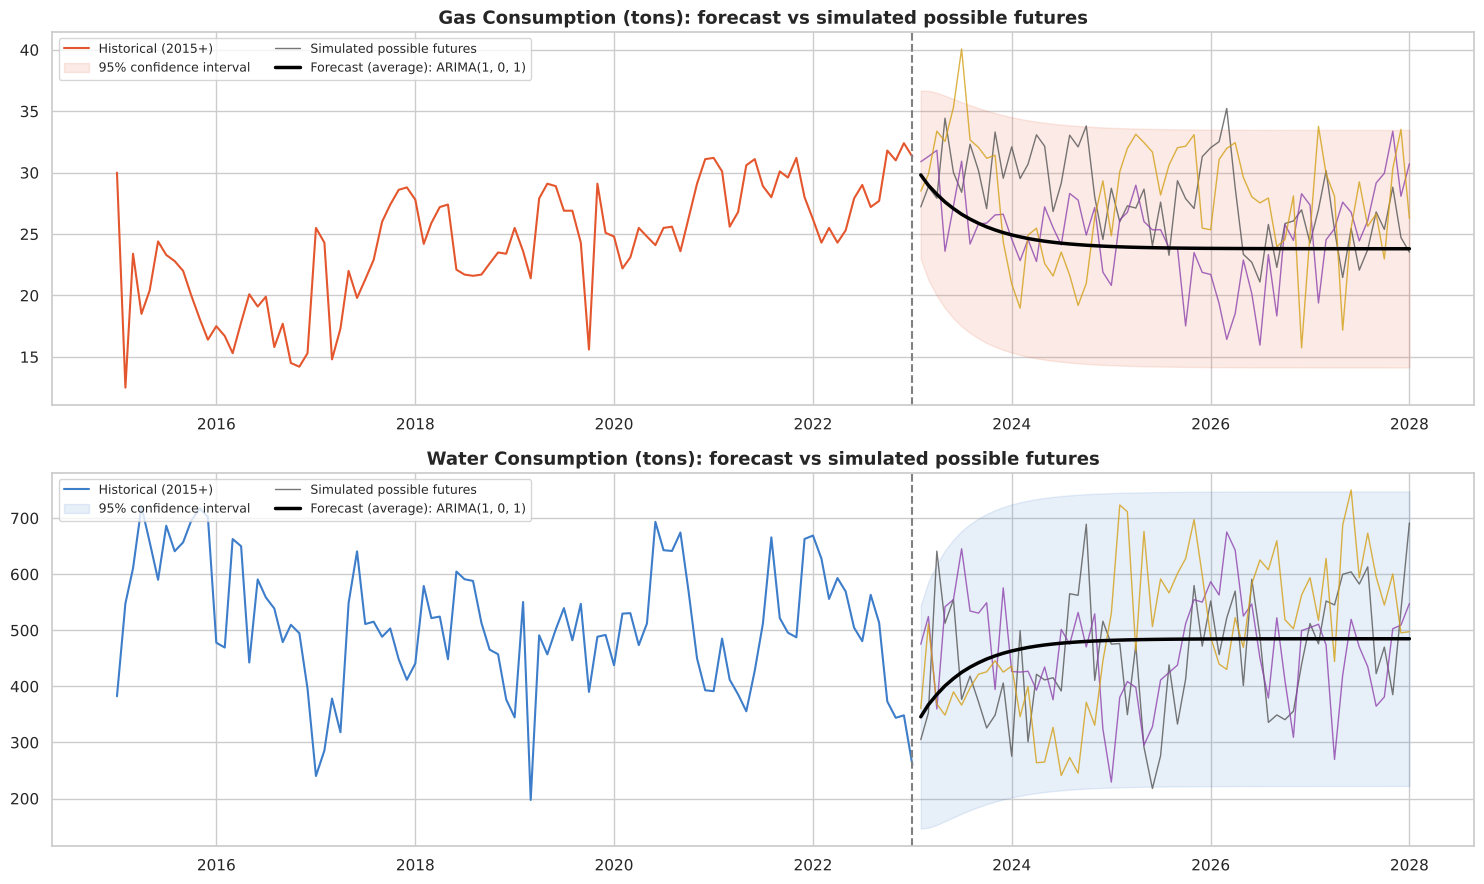

In [24]:
N_PATHS = 3
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
for ax, u in zip(axes, [GAS, WATER]):
    name, fit = final_specs[u]
    model = fit(df[u])
    fc = model.get_forecast(H)
    mean, ci = fc.predicted_mean, fc.conf_int(alpha=0.05)
    np.random.seed(42)   # same simulated paths each time the notebook runs
    paths = model.simulate(nsimulations=H, anchor="end", repetitions=N_PATHS)
    paths = pd.DataFrame(np.asarray(paths).reshape(H, N_PATHS), index=mean.index)

    hist = df[u].loc["2015":]
    ax.plot(hist.index, hist, color=COLORS[u], linewidth=1.5, label="Historical (2015+)")
    ax.fill_between(mean.index, ci.iloc[:, 0], ci.iloc[:, 1], color=COLORS[u], alpha=0.12, label="95% confidence interval")
    for j in range(N_PATHS):
        ax.plot(paths.index, paths[j], color=["#555555", "#8E44AD", "#D4A017"][j], linewidth=1, alpha=0.8,
                label="Simulated possible futures" if j == 0 else None)
    ax.plot(mean.index, mean, color="black", linewidth=2.5, label=f"Forecast (average): {name}")
    ax.axvline(df.index[-1], color="grey", linestyle="--")
    ax.set_title(f"{u}: forecast vs simulated possible futures", fontsize=13, fontweight="bold")
    ax.legend(loc="upper left", fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

**Observations**

- Every simulated path **zigzags like the real data**, but each one zigzags **differently**: the ups and downs land in different months. The model knows the swings will happen, but not *when* or *in which direction*.
- The black forecast line is the **average of all possible futures**. Because the random swings are equally likely to go up or down, they cancel out when averaged, which leaves a smooth line that settles at the long-run average.
- The swings are not ignored. They are what the **95% confidence band** represents: about 95% of simulated months fall inside it, with the odd month breaking out, just like real data.
- A zigzag forecast would only be justified if the timing of the swings were predictable, as with electricity's yearly cycle, which is why the electricity forecast does wiggle. For gas and water, adding seasonal terms to force a wiggle made validation accuracy worse or no better (Step 9.1).

**In short:** a flat forecast does not mean the model expects consumption to stay flat. It means the best single estimate for each month is the average, and the band shows how far real months are likely to swing around it.

## Step 9: Model Improvement Analysis
### 9.1 Impact of Seasonality

Each utility's model is compared **with and without** a seasonal component on the validation set.

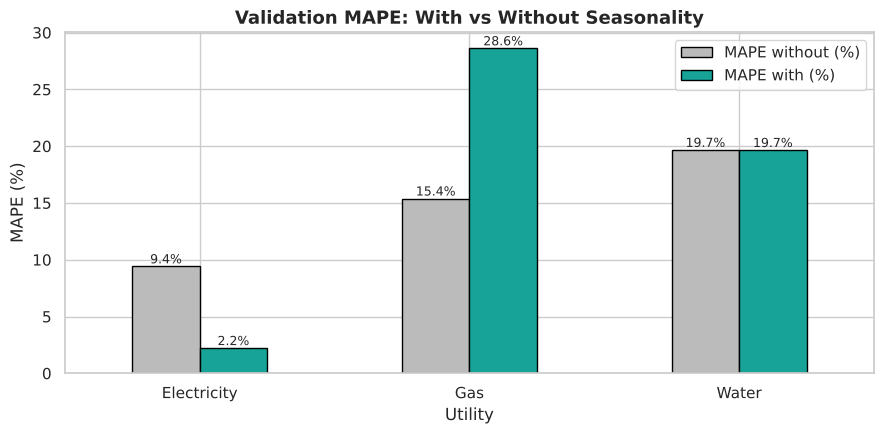

,MAPE without (%),MAPE with (%),RMSE without,RMSE with
Utility,,,,
Electricity,9.42,2.22,127.53,29.50
Gas,15.39,28.62,3.91,8.02
Water,19.67,19.66,99.11,100.55


In [25]:
season_rows = []
pairs = [
    (ELEC, ARIMA(tr_elec, order=(0, 1, 1)), SARIMAX(tr_elec, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))),
    (GAS, ARIMA(tr_gas, order=best_gas_order), SARIMAX(tr_gas, order=best_gas_order, seasonal_order=(1, 0, 1, 12))),
    (WATER, ARIMA(tr_water, order=best_water_order), SARIMAX(tr_water, order=best_water_order, seasonal_order=(1, 0, 1, 12))),
]
for u, m_no, m_yes in pairs:
    no = evaluate(val[u], m_no.fit().forecast(h), "No seasonality")
    yes = evaluate(val[u], m_yes.fit(disp=False).forecast(h), "With seasonality")
    season_rows.append({"Utility": u.split(" ")[0], "MAPE without (%)": no["MAPE (%)"], "MAPE with (%)": yes["MAPE (%)"],
                        "RMSE without": no["RMSE"], "RMSE with": yes["RMSE"]})
season_df = pd.DataFrame(season_rows).set_index("Utility")

ax = season_df[["MAPE without (%)", "MAPE with (%)"]].plot(kind="bar", figsize=(9, 4.5), color=["#BBBBBB", "#17A398"], edgecolor="black")
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", fontsize=9)
plt.title("Validation MAPE: With vs Without Seasonality", fontsize=13, fontweight="bold")
plt.ylabel("MAPE (%)"); plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
season_df.round(2)

| Utility | MAPE without seasonality | MAPE with seasonality | Effect |
|---|---|---|---|
| **Electricity** | 9.42% | **2.22%** | **76% lower error** |
| **Gas** | **15.39%** | 28.62% | Much worse |
| **Water** | 19.67% | 19.66% | No change (RMSE 99.11 → 100.55, slightly worse) |

- **Electricity:** adding seasonality cut the error from **9.42% to 2.22%**, a 7.2 percentage-point drop or **76% in relative terms**. This is the **single biggest improvement in the project**, and it reflects electricity's strong yearly cycle.
- **Gas:** adding seasonality nearly **doubled** the error. Gas has only a weak seasonal pattern (about ±1 ton in the decomposition), so the extra seasonal parameters end up fitting noise.
- **Water:** seasonal terms add parameters for **no gain**, so the simpler non-seasonal model is kept. The faint yearly pattern in the residuals (Step 7.1) is too weak to improve the forecasts.

**Takeaway:** only add seasonality when the data actually shows a seasonal pattern.

### 9.2 Impact of Hyperparameter Tuning
With validation over four windows, tuning improved **electricity by 10.1%** and **water by 6.8%** (against the Mean), and left gas unchanged (Step 6). The electricity gain came from choosing the **right amount of differencing** (d = 0 instead of d = 1). The water gain came from showing that ARIMA beats the Mean over a longer history. The fine-tuning of p and q mattered much less: for gas and water, the top five configurations are within about 2% of each other.

**Overall:** the biggest improvements came from **understanding the data**: whether to include seasonality, and how much to difference. Searching over parameter values mattered much less.

### 9.3 Impact of Keeping the February 2014 Outlier

The outlier was kept in Step 2. That choice is an assumption, so it is tested here: the chosen gas and water models are refitted with **February 2014 replaced by the average of the months either side**, and both versions are scored on the validation set (the outlier sits in the training data).

In [26]:
out_rows = []
for u, order in [(GAS, best_gas_order), (WATER, best_water_order)]:
    cleaned = train[u].copy()
    cleaned.loc["2014-02-01"] = np.nan
    cleaned = cleaned.interpolate()
    for label, s in [("Outlier kept", train[u]), ("Outlier smoothed", cleaned)]:
        r = evaluate(val[u], ARIMA(s, order=order).fit().forecast(h), label)
        out_rows.append({"Utility": u.split(" ")[0], "Feb 2014 value used": s.loc["2014-02-01"],
                         "Version": label, "Val RMSE": r["RMSE"], "Val MAPE (%)": r["MAPE (%)"]})
pd.DataFrame(out_rows).round(2)

,Utility,Feb 2014 value used,Version,Val RMSE,Val MAPE (%)
0,Gas,46.00,Outlier kept,3.91,15.39
1,Gas,18.00,Outlier smoothed,3.98,15.71
2,Water,44.40,Outlier kept,99.11,19.67
3,Water,594.95,Outlier smoothed,98.89,19.67


- **Gas:** smoothing the outlier changes validation RMSE from 3.91 to 3.98 (about **2% worse**).
- **Water:** smoothing changes RMSE from 99.11 to 98.89 (about **0.2% better**).

Either way, the effect is **negligible**. One unusual month out of 317 barely moves the estimated model parameters. Keeping the outlier therefore does not distort the models, and since we cannot confirm whether February 2014 was a real event or a data error, the original value is kept.

### 9.4 Would Forcing a Seasonal Pattern Help Gas and Water?

The gas and water forecasts are flat lines. Seasonal models would produce forecasts that *look* more like the real data, so several seasonal alternatives are tested here: a seasonal SARIMA, Holt-Winters with a 12-month season, and Holt-Winters with much longer "seasons" of 36 and 60 months. Each is scored on the **same four validation windows** used in Step 6.

The **test MAPE** is shown only to explain why seasonal models can look better on a single period. It was **not** used to choose any model.

In [27]:
alternatives = {
    GAS: {
        "ARIMA(1,0,1) (chosen)": lambda s, k: ARIMA(s, order=best_gas_order).fit().forecast(k),
        "SARIMA(1,0,1)(1,0,0,12)": lambda s, k: SARIMAX(s, order=(1, 0, 1), seasonal_order=(1, 0, 0, 12),
            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False).forecast(k),
        "Holt-Winters, 60-month season": lambda s, k: ExponentialSmoothing(s, trend="mul", seasonal="add",
            seasonal_periods=60, damped_trend=True).fit().forecast(k),
    },
    WATER: {
        "ARIMA(1,0,1) (chosen)": lambda s, k: ARIMA(s, order=best_water_order).fit().forecast(k),
        "Holt-Winters, 12-month season": lambda s, k: ExponentialSmoothing(s, trend="add", seasonal="add",
            seasonal_periods=12, damped_trend=True).fit().forecast(k),
        "Holt-Winters, 36-month season": lambda s, k: ExponentialSmoothing(s, trend="mul", seasonal="mul",
            seasonal_periods=36).fit().forecast(k),
        "SARIMA(0,0,0)(1,1,0,12)": lambda s, k: SARIMAX(s, order=(0, 0, 0), seasonal_order=(1, 1, 0, 12),
            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False).forecast(k),
    },
}
alt_rows = []
for u, models in alternatives.items():
    chosen_rmse = None
    for name, fn in models.items():
        cv_res = rolling_cv(trval[u], fn)
        chosen_rmse = chosen_rmse or cv_res["CV RMSE"]
        test_res = evaluate(test[u], fn(trval[u], len(test)), name)
        alt_rows.append({"Utility": u.split(" ")[0], "Model": name,
                         "CV RMSE": cv_res["CV RMSE"], "CV MAPE (%)": cv_res["CV MAPE (%)"],
                         "vs chosen (%)": (cv_res["CV RMSE"] / chosen_rmse - 1) * 100,
                         "Test MAPE (%) - not used for selection": test_res["MAPE (%)"]})
pd.DataFrame(alt_rows).round(2)

,Utility,Model,CV RMSE,CV MAPE (%),vs chosen (%),Test MAPE (%) - not used for selection
0,Gas,"ARIMA(1,0,1) (chosen)",4.47,17.55,0.00,15.03
1,Gas,"SARIMA(1,0,1)(1,0,0,12)",5.71,21.06,27.56,11.49
2,Gas,"Holt-Winters, 60-month season",5.33,21.28,19.05,11.55
3,Water,"ARIMA(1,0,1) (chosen)",139.81,30.42,0.00,17.77
4,Water,"Holt-Winters, 12-month season",161.60,39.56,15.59,17.60
5,Water,"Holt-Winters, 36-month season",203.14,49.33,45.30,18.87
6,Water,"SARIMA(0,0,0)(1,1,0,12)",162.31,37.51,16.09,17.46


**Observations**

- **Every seasonal alternative is worse on validation**, by between about 16% and 45% in average RMSE. The chosen non-seasonal models remain the best for both gas and water.
- **The 36- and 60-month "seasons" are not supported by the data.** The decomposition (Step 2) found only a weak 12-month pattern, and no 3- or 5-year cycle. A model with a 60-month season learns the shape of one 5-year stretch and copies it forward. That produces a wiggly forecast, but the wiggles are a copy of past noise, not a real pattern. A 39-month validation window cannot even contain one full 60-month cycle, which makes such a model impossible to validate properly.
- **Some seasonal gas models score better on the test set.** For example, the 60-month Holt-Winters has a test MAPE of about 11.6% against 15.0% for the chosen model. This is not because of seasonality. These models do not pull the forecast back to the long-run average, which happened to suit the 2020–2022 rise in gas. The same behaviour made them worse in the four validation windows, where gas did return to its average.
- **Why the test score is not used to switch models:** choosing a model because it did well on the test set would turn the test set into a second validation set. The test score would then no longer be an honest measure of performance on unseen data.

**Conclusion:** a forecast that *looks* like the real data is not the same as an accurate forecast. The flat gas and water forecasts are kept because they have the lowest validation error, and the confidence band (Step 8.1) shows the swings that cannot be predicted.

## Final Conclusion

### Project Summary
This project forecast a building's monthly **gas, electricity and water consumption** for the next **60 months** (February 2023 – January 2028), using **397 months of data (January 1990 – January 2023)**. The goal was forecasts that are accurate enough to support utility budgeting and capacity planning, along with an honest picture of how uncertain each forecast is.

### Key Findings from the Data
- **The three utilities behave very differently.** All pairwise correlations are below 0.4 in absolute value (Gas ↔ Electricity +0.14, Electricity ↔ Water +0.22, Gas ↔ Water −0.39), so each utility was modelled **separately**.
- **Electricity** has a clear upward trend (the 12-month rolling mean rises from about 675 to about 1,010 MWh in the training data) that **levels off after about 2013**, plus a **strong yearly cycle** (about −95 to +135 MWh).
- **Gas** has no long-term growth. Its level moves in slow waves lasting several years but **keeps returning to an average of about 24 tons**, and its seasonality is very weak (about ±1 ton).
- **Water** is **mostly irregular noise**: residuals of up to about ±470 tons, against a seasonal pattern of only about −38 to +45 tons.
- **February 2014** is the only anomaly: gas doubled (46 tons, Z = 4.54) while water almost stopped (44 tons, Z = 3.29) in the same month. This points to a single event or a metering problem rather than two coincidences.

### Final Models and Results

| Utility | Final model | Validation MAPE (4-window avg) | Test MAPE | Test RMSE | Bias | Residuals |
|---|---|---|---|---|---|---|
| **Electricity** | SARIMA(1,0,2)(0,1,1)₁₂ | 2.83% | **2.61%** | 36.76 MWh | −7.6 MWh | Mostly white noise |
| **Gas** | ARIMA(1,0,1) | 17.55% | **15.03%** | 5.06 tons | +3.4 tons | White noise |
| **Water** | ARIMA(1,0,1) | 30.42% | **17.77%** | 106.38 tons | +19.7 tons | White noise |

All final models converged. Electricity and gas have similar error on validation and test, so they **generalise** to unseen data. Water's lower test error reflects a calmer test period, not a better model.

### What Worked
1. **Modelling seasonality for electricity.** This was the single biggest improvement: validation MAPE fell from **9.42% to 2.22%** (76% lower). Electricity's yearly cycle is strong and regular, so a seasonal model can predict it.
2. **Deciding on differencing separately for each utility.** Stationarity was judged with the ADF test, rolling statistics and visual inspection together. Only electricity was differenced, and the grid searches confirmed the decisions:
   - Gas with d = 1 was 5.6% worse (4.72 vs 4.47 RMSE).
   - Water with d = 1 was about 10% worse (153.21 vs 139.81).
   - For electricity, a **seasonal difference alone** (d = 0, D = 1) beat differencing twice (d = 1, D = 1). This gave a **10.1%** improvement over the baseline and a realistic, nearly flat long-term forecast.
3. **Comparing against simple benchmarks.** Seasonal Naive and Mean benchmarks showed whether each model was actually worth using. On the single validation window, no model beat the Mean for water. Over four windows, ARIMA(1,0,1) beat the Mean by **6.8%**.
4. **Validating on four windows (rolling-origin validation).** On the single original validation window, SARIMA(0,1,1)(1,1,1)₁₂ looked best (RMSE 29.47). Averaged over four windows it was **11% worse** than the chosen model. Scoring each model on several windows avoided picking a model that only suited 2016–2019.
5. **Preferring simpler models when scores were tied.** When configurations were within 1% of each other, the one with the fewest terms was chosen, e.g. ARIMA(1,0,1) over ARIMA(1,0,2) for gas. This reduces the risk of overfitting.

### What Did Not Work
1. **Seasonal terms for gas and water.** Adding seasonality nearly **doubled** the gas error (15.39% → 28.62% MAPE) and gave **no gain** for water (19.67% → 19.66%). Their seasonal patterns are too weak, so the extra parameters only fitted noise.
2. **Differencing gas and water.** This made every forecast worse, because it throws away the fact that both series keep returning to their usual level.
3. **Extra differencing for electricity (d = 1 on top of D = 1).** It differenced the series twice and carried the old upward trend into the forecast, even though growth had stopped around 2013.
4. **Other candidate models:**
   - **ETS for gas** was no better than Seasonal Naive (both RMSE 6.27).
   - **Holt-Winters for electricity** was less accurate than SARIMA (34.04 vs 29.50 RMSE).
   - **The 12-month moving average for water** was the worst model (38.12% MAPE), because it chases recent swings that don't continue.
5. **Fine-tuning p and q.** This changed little: the top five configurations for gas and water are within about 2% of each other. **Choosing the right type of model mattered far more than its exact parameters.**
6. **Removing the February 2014 outlier** made almost no difference (gas RMSE 3.91 → 3.98, water 99.11 → 98.89), so it was kept.
7. **Forcing seasonality onto gas and water.** Seasonal SARIMA and Holt-Winters models with 12-, 36- and 60-month seasons produce forecasts that look more realistic, but they scored 16–45% worse across the four validation windows (Step 9.4).

### 60-Month Forecast and Planning Recommendations

| Utility | Forecast (average per month) | 95% interval by 2028 | Recommendation |
|---|---|---|---|
| **Electricity** | About 1,055 MWh (2024) → 1,072 MWh (2027), about +0.5% per year; January peaks of about 1,225–1,250 MWh | Interval widens over time | Budget for roughly flat use with strong January peaks; use the upper band for capacity planning |
| **Gas** | Returns from about 30 to about **23.8 tons** within about 2 years | 14.1 – 33.5 tons | Recent use is about 28 tons. Monitor and refit quarterly; if the higher level persists, the long-run average has shifted |
| **Water** | Rises from about 346 back to about **485 tons** | 222 – 748 tons | Treat as a rough average only. Investigate the causes of the large swings |

**Why the gas and water forecasts are flat:** each forecast line is the **average of all possible futures**. Their month-to-month swings don't happen at predictable times, so they cancel out in the average and show up in the confidence band instead (Step 8.1). Electricity's forecast wiggles because its yearly cycle *is* predictable.

### Limitations
- **Gas** under-predicted the 2020–2022 rise: every test error from October 2020 onwards is positive. No model based only on gas's own history can foresee this kind of shift in level, and differencing did not help.
- **Electricity** residuals show a small leftover pattern at 24 lags (Ljung-Box p = 0.005), probably because the seasonal swings grow as consumption grows.
- **Water** is only modestly better than the historical mean (30% average validation MAPE). Most of its variation can't be explained by its own history.
- **The test set (41 months) is shorter than the 60-month forecast,** so accuracy in the last year or so of the forecast is not directly measured.
- **Only the utilities' own past values were used.** No outside factors such as weather, occupancy or operations data were included.


### Future Work
- **Electricity:** apply a **log transform** so the seasonal swings have a constant size, which may remove the leftover residual pattern.
- **Gas:** **refit regularly** on recent data, and add outside variables (for example, equipment or operational changes) to capture shifts in level.
- **Water:** collect **outside data** such as occupancy, weather and maintenance schedules, which is likely needed to forecast it properly.
- **Data quality:** confirm with the facility whether **February 2014** was a real event or a data error.

### Overall Takeaway
The biggest gains came from **understanding the data**, not from the most complex model or the longest parameter search. That meant modelling seasonality only where it exists, differencing only where the series is non-stationary, and judging every choice by validation error across several windows. Electricity can be forecast very accurately (2.6% MAPE). Gas and water are limited mainly by the information available in their own history, so the next step for them is better data rather than more complex models.